# Weather Model Bias Analysis and Calibration

This notebook is divided into two parts:

- **Part 1: Bias Analysis (EDA):** analyzes the forecast bias of **eight AI weather models** across different weather variables and time scales (hourly, daily, monthly, and yearly) to understand where and why prediction errors occur.

- **Part 2: Bias Calibration:** uses the findings from Part 1 to train **MLP, SVR, Random Forest, and LightGBM** models that predict and correct the forecast bias for **2-meter temperature (`t2m`)** and **6-hour accumulated precipitation (`tp06`)**.

# Part 1: Bias Analysis (EDA)

In [2]:
# Import the libraries we need
import os
import pandas as pd
import numpy as np

from scipy.stats import f_oneway

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import LabelEncoder

In [3]:
# Make sure the output folders exist before saving files
os.makedirs('../results/tables', exist_ok=True)
os.makedirs('../results/figures', exist_ok=True)

## 1. Load the data

In [4]:
# Load the dataset
df = pd.read_csv('../data/dataset_fusionnée.csv')
print('Rows number:', len(df))
print('Models:', df['model'].unique().tolist())
print('Variables:', df['variable_name'].unique().tolist())
df

Rows number: 302853
Models: ['dlwp', 'graphcast', 'fourcastnet', 'aurora', 'pangu6', 'fuxi', 'fengwu', 'aifs', 'arome']
Variables: ['t2m', 'msl', 'tp06', 'sp', 'td2m']


,run_time,lead_time,model,station,distance_km,lat,lon,variable_name,pred_value,valid_time,obs_value,biais,erreur_abs,erreur_sq
0,2025-09-04,0,dlwp,LAAYOUNE,11.541602,27.250000,-13.250000,t2m,20.277063,2025-09-04 00:00:00,21.8,-1.522937,1.522937,2.319337
1,2025-09-04,0,dlwp,SIDI-IFNI,14.550544,29.250000,-10.250000,t2m,19.077051,2025-09-04 00:00:00,19.6,-0.522949,0.522949,0.273476
2,2025-09-04,0,dlwp,TANGER-AERO,8.921653,35.750000,-6.000000,t2m,22.777063,2025-09-04 00:00:00,23.3,-0.522937,0.522937,0.273463
3,2025-09-04,0,dlwp,LARACHE,14.357404,35.250000,-6.000000,t2m,21.477045,2025-09-04 00:00:00,22.5,-1.022955,1.022955,1.046438
4,2025-09-04,0,dlwp,EL-HOCEIMA,11.341883,35.250000,-3.750000,t2m,21.877039,2025-09-04 00:00:00,19.3,2.577039,2.577039,6.641128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302848,2026-03-31,18,arome,AIT-MELLOUL,0.000000,30.322480,-9.406004,t2m,19.591180,2026-03-31 18:00:00,19.8,-0.208820,0.208820,0.043606
302849,2026-03-31,18,arome,TIZNIT,0.000000,29.684563,-9.729860,t2m,19.757440,2026-03-31 18:00:00,20.1,-0.342560,0.342560,0.117347
302850,2026-03-31,18,arome,TANTAN,0.000000,28.446637,-11.158312,t2m,22.816827,2026-03-31 18:00:00,20.3,2.516827,2.516827,6.334420
302851,2026-03-31,18,arome,TETOUAN,0.000000,35.592694,-5.331712,t2m,20.009943,2026-03-31 18:00:00,21.9,-1.890057,1.890057,3.572317


In [19]:
# Remove the AROME model because it is Mohammed's work
df = df[df['model'] != 'arome'].copy()
print('Models kept:', df['model'].unique().tolist())
print('Rows left:', len(df))
df
df.to_csv(os.path.join('../results/tables', 'dataset_fusionnée.csv'),index=False)

Models kept: ['dlwp', 'graphcast', 'fourcastnet', 'aurora', 'pangu6', 'fuxi', 'fengwu', 'aifs']
Rows left: 261082


In [6]:
# Convert valid_time from text to a date_time
print("Before converting valid_time to a date_time, its type is: ",df['valid_time'].dtype)
df['valid_time'] = pd.to_datetime(df['valid_time'])
print("After converting valid_time to a date_time, its type is: ",df['valid_time'].dtype)

Before converting valid_time to a date_time, its type is:  str
After converting valid_time to a date_time, its type is:  datetime64[us]


In [7]:
# Display summary statistics for all numerical columns to get a quick overview of the dataset
df.describe()

,lead_time,distance_km,lat,lon,pred_value,valid_time,obs_value,biais,erreur_abs,erreur_sq
count,261082.000000,261082.000000,261082.000000,261082.000000,261082.000000,261082,261082.000000,261082.000000,261082.000000,261082.000000
mean,60.122467,20.947469,32.080695,-7.649938,81.629724,2025-12-10 20:37:09.782213,81.487210,0.142515,2.121982,20.979625
min,0.000000,2.408429,23.574800,-16.313283,-15.730762,2025-09-04 00:00:00,-18.000000,-71.515381,0.000000,0.000000
25%,54.000000,8.099556,30.500000,-9.500000,0.007757,2025-10-16 00:00:00,0.000000,-0.692081,0.011898,0.000142
50%,60.000000,12.637908,33.000000,-7.500000,15.741403,2025-11-30 00:00:00,15.200000,0.000149,1.062146,1.128154
75%,66.000000,36.781128,34.000000,-5.500000,21.152852,2026-02-12 12:00:00,20.600000,1.452640,2.705671,7.320654
max,72.000000,65.047773,36.000000,-2.000000,1035.705547,2026-03-31 18:00:00,1034.000000,59.871132,71.515381,5114.449677
std,11.251087,17.276810,2.793567,2.988019,252.224663,NaN,253.077517,4.578143,4.059173,182.161174


The dataset contains **261,082 observations** with no missing numerical values. Forecast lead times range from **0 to 72 hours**, and the distance between weather stations and their corresponding model grid points varies from approximately **2.4 km** to **65.0 km**. Since the dataset combines several weather variables with different physical units (such as temperature, pressure, and precipitation), summary statistics for variables such as **`pred_value`**, **`obs_value`**, and **`biais`** should be interpreted with caution, as they do not represent a single physical quantity.

## 2. Data coverage by model:

In [8]:
coverage = df.groupby(['model', 'variable_name']).size().unstack()
coverage

variable_name,msl,sp,t2m,td2m,tp06
model,,,,,
aifs,2136.0,2497.0,24611.0,2508.0,23700.0
aurora,1880.0,NaN,21474.0,NaN,NaN
dlwp,NaN,NaN,21474.0,NaN,NaN
fengwu,1880.0,NaN,21474.0,NaN,NaN
fourcastnet,1880.0,2168.0,21474.0,NaN,NaN
fuxi,1880.0,NaN,21474.0,NaN,20932.0
graphcast,1880.0,NaN,21474.0,NaN,20932.0
pangu6,1880.0,NaN,21474.0,NaN,NaN


Checking the data for each model and weather variable shows which calibration methods are possible. **AIFS** has all five weather variables, so it is the only model for **multi-variable calibration**. The other models have fewer variables, and **DLWP** only has **temperature (t2m)**.

In [9]:
# Add the hour and month from valid_time.
df['hour'] = df['valid_time'].dt.hour
df['month'] = df['valid_time'].dt.month

## 3. Bias per hour, day, month and year
For every model and every variable.

In [10]:
# Mean bias per hour of the day (0h to 23h)
df_hourly = df.groupby(['model', 'variable_name', 'hour'])['biais'].mean().reset_index()
df_hourly.to_csv(os.path.join('../results/tables', 'bias_hourly.csv'),index=False)
print('Hourly rows:', len(df_hourly))
df_hourly.head()

Hourly rows: 84


,model,variable_name,hour,biais
0,aifs,msl,0,-1.364465
1,aifs,msl,6,1.049776
2,aifs,msl,12,-0.919583
3,aifs,msl,18,1.284817
4,aifs,sp,0,-17.190165


In [11]:
# Mean bias for each date
df_daily = df.groupby(['model', 'variable_name', df['valid_time'].dt.date.rename('date')])['biais'].mean().reset_index()
df_daily.to_csv(os.path.join('../results/tables', 'bias_daily.csv'),index=False)
print('Daily rows:', len(df_daily))
df_daily.head()

Daily rows: 3706


,model,variable_name,date,biais
0,aifs,msl,2025-09-04,-1.187620
1,aifs,msl,2025-09-05,0.344865
2,aifs,msl,2025-09-06,1.415709
3,aifs,msl,2025-09-07,1.625826
4,aifs,msl,2025-09-08,1.286487


In [12]:
# Mean bias per month
df_monthly = df.groupby(['model', 'variable_name', df['valid_time'].dt.to_period('M').rename('month')])['biais'].mean().reset_index()
df_monthly.to_csv(os.path.join('../results/tables', 'bias_monthly.csv'),index=False)
print('Monthly rows:', len(df_monthly))
df_monthly.head()

Monthly rows: 147


,model,variable_name,month,biais
0,aifs,msl,2025-09,0.639404
1,aifs,msl,2025-10,0.231495
2,aifs,msl,2025-11,0.035745
3,aifs,msl,2025-12,0.073578
4,aifs,msl,2026-01,-0.098210


In [13]:
# Mean bias per year
df_annual = df.groupby(['model', 'variable_name', df['valid_time'].dt.year.rename('year')])['biais'].mean().reset_index()
df_annual.to_csv(os.path.join('../results/tables', 'bias_annual.csv'),index=False)
print('Annual rows:', len(df_annual))
df_annual.head()

Annual rows: 42


,model,variable_name,year,biais
0,aifs,msl,2025,0.225947
1,aifs,msl,2026,-0.206984
2,aifs,sp,2025,-16.544306
3,aifs,sp,2026,-14.479405
4,aifs,t2m,2025,-0.098094


## 4. Model Performance
We compare the models using **bias**, **MAE**, and **RMSE**. MAE and RMSE show the prediction error.

In [14]:
# Calculate bias, MAE, RMSE, and the number of pairs for each model and variable.
model_performance = df.groupby(['model', 'variable_name']).agg(
    mean_bias=('biais', 'mean'),
    mae=('erreur_abs', 'mean'),
    rmse=('erreur_sq', lambda x: np.sqrt(x.mean())),
    n_pairs=('biais', 'size')
).reset_index()

model_performance.sort_values(['variable_name', 'rmse'],inplace=True)
model_performance.to_csv(os.path.join('../results/tables', 'error_summary_per_model.csv'), index=False)

model_performance

,model,variable_name,mean_bias,mae,rmse,n_pairs
8,fengwu,msl,-0.283232,0.960835,1.264144,1880
13,fuxi,msl,-0.280629,0.987023,1.306690,1880
5,aurora,msl,-0.493823,1.047440,1.351836,1880
19,pangu6,msl,-0.504860,1.061728,1.398688,1880
10,fourcastnet,msl,-0.316897,1.148134,1.497359,1880
0,aifs,msl,0.030966,2.364809,3.068448,2136
16,graphcast,msl,0.653854,3.923533,4.939097,1880
11,fourcastnet,sp,-6.868556,11.505874,15.284498,2168
1,aifs,sp,-15.623908,23.315557,32.689200,2497
6,aurora,t2m,0.184030,1.612378,2.124240,21474


Bias alone is not enough because positive and negative errors can cancel each other. **Aurora, Fengwu, Pangu6, Fuxi, and FourCastNet** are the best models for **temperature (t2m)**, with RMSE between **2.1°C and 2.3°C**. **GraphCast, DLWP, and AIFS** have the largest errors (**4.5°C–5.1°C**) and need calibration the most. For **surface pressure (sp)**, the high RMSE of **AIFS** is probably caused by station altitude. For **precipitation (tp06)**, the low RMSE should be treated carefully because most observations have no rain.

## 5. Bias Over Time

We use one function to plot the bias by **hour**, **day**, **month**, and **year**.

In [15]:
# Function to plot mean bias vs a time column, for one variable
def plot_bias_over_time(data, time_col, variable, x_label, file_name):
    subset = data[data['variable_name'] == variable].copy()
    if subset.empty:
        return

    is_date = (time_col == 'date')
    if is_date:
        subset[time_col] = pd.to_datetime(subset[time_col]) # Convert dates to keep the correct order.
    else:
        subset[time_col] = subset[time_col].astype(str)# Keep hours, months, and years as text.

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.lineplot(data=subset, x=time_col, y='biais', hue='model', marker='o', ax=ax)

    # Format the x-axis for dates
    if is_date:
        ax.xaxis.set_major_locator(mdates.AutoDateLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

    plt.title(f'Mean bias vs {x_label} - {variable}')
    plt.xlabel(x_label)
    plt.ylabel('Mean bias')
    plt.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.axhline(0, color='black')
    plt.tight_layout()
    plt.savefig(f"../results/figures/{file_name}")
    plt.show()

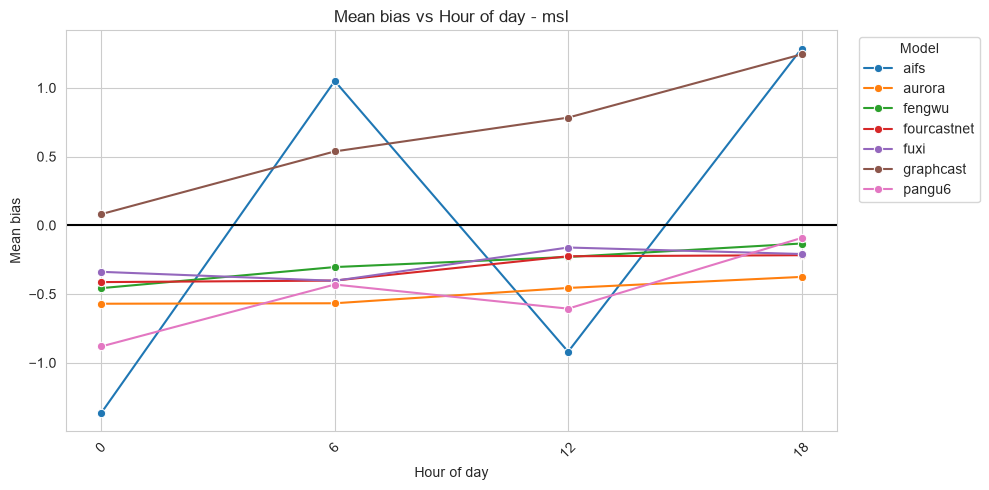

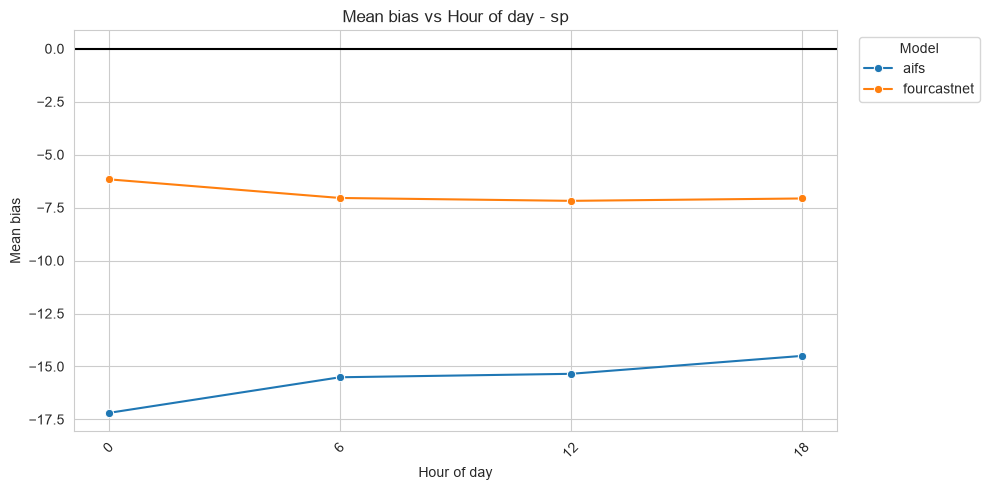

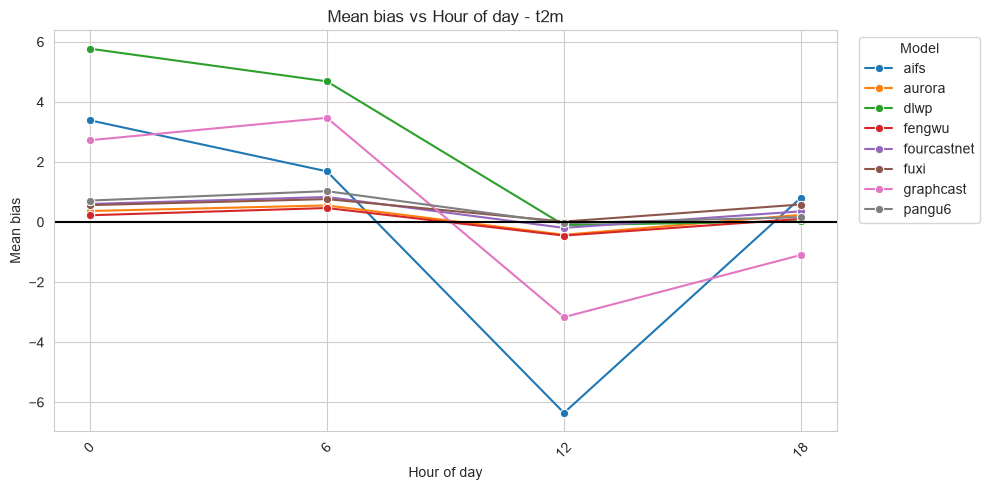

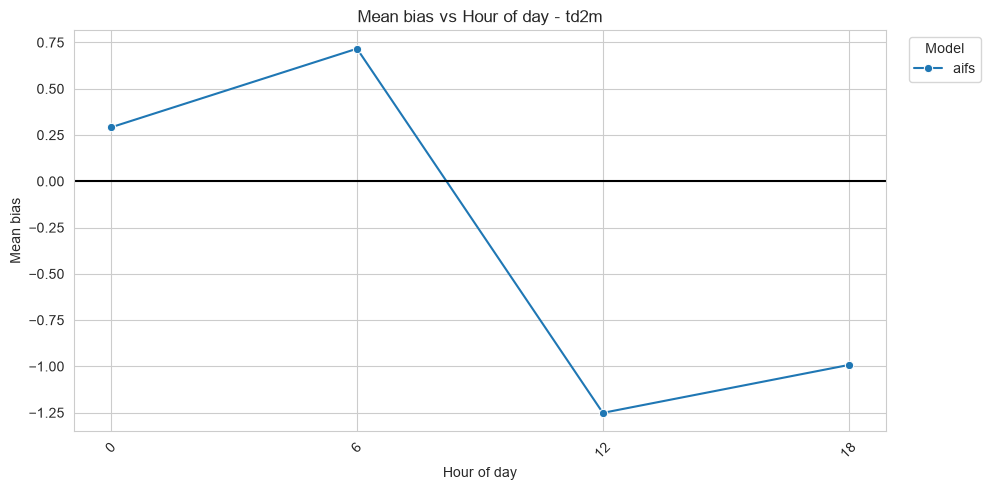

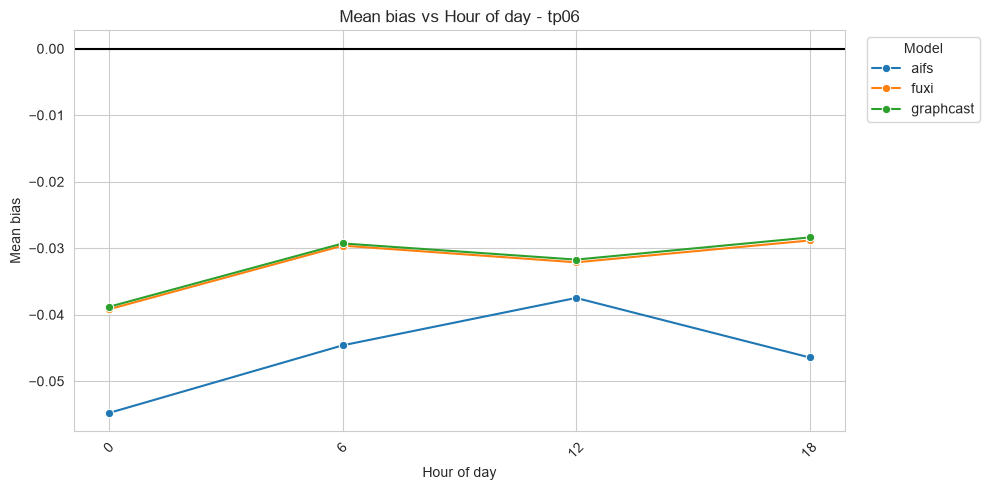

In [16]:
# Hourly bias plot, for every variable
for var in sorted(df['variable_name'].unique()):
    plot_bias_over_time(df_hourly, 'hour',var,'Hour of day', f'hourly_bias_{var}.png')

The hourly bias shows if model errors change during the day. **AIFS, DLWP, and GraphCast** have the largest changes, while the other models stay close to zero. For **temperature (t2m)**, **AIFS** changes from **+3.4°C at night** to **−6.4°C at noon**. For **surface pressure (sp)**, **AIFS** and **FourCastNet** have a negative bias at all hours.

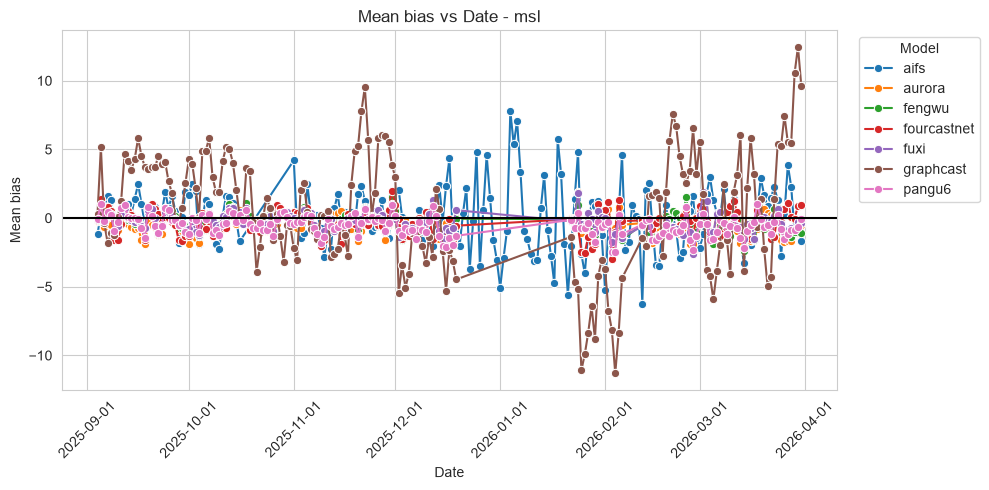

In [17]:
# Daily bias plot, for every variable
for var in sorted(df['variable_name'].unique()):
    plot_bias_over_time(df_daily, 'date', var, 'Date', f'daily_bias_{var}.png')

The daily bias shows how model errors change from day to day. **GraphCast** changes the most for **msl** and **t2m**, while **DLWP** is more stable and usually overestimates **temperature (t2m)**.

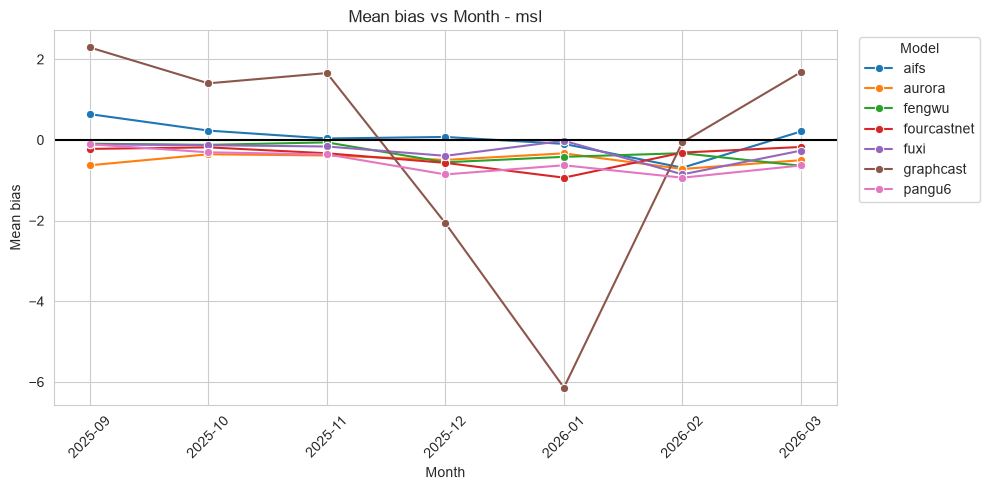

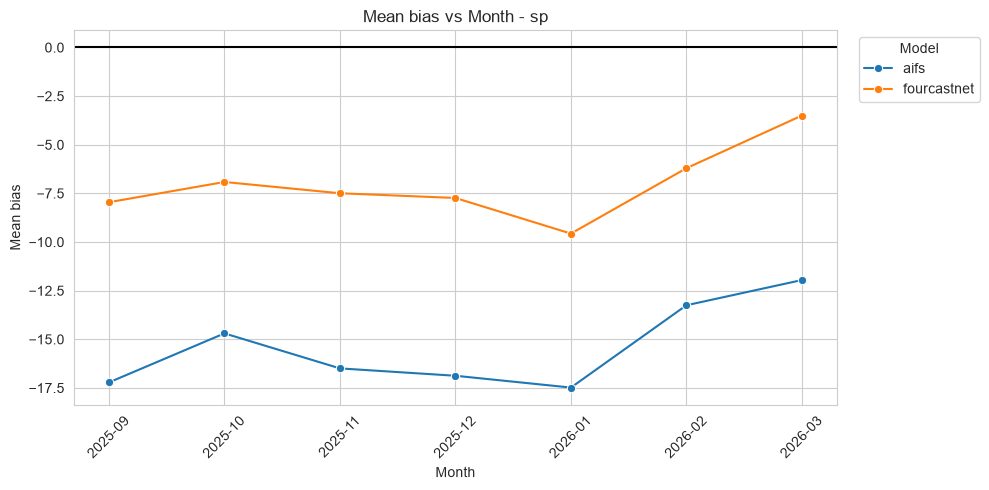

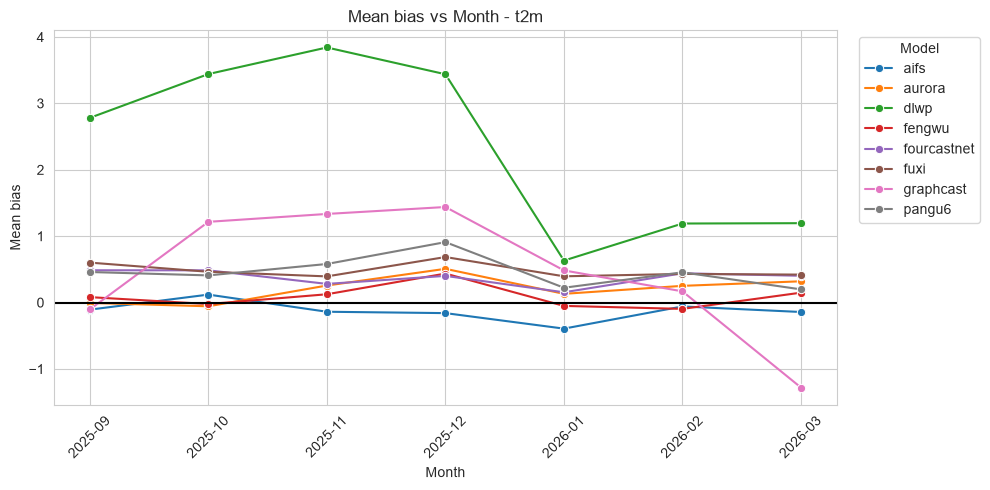

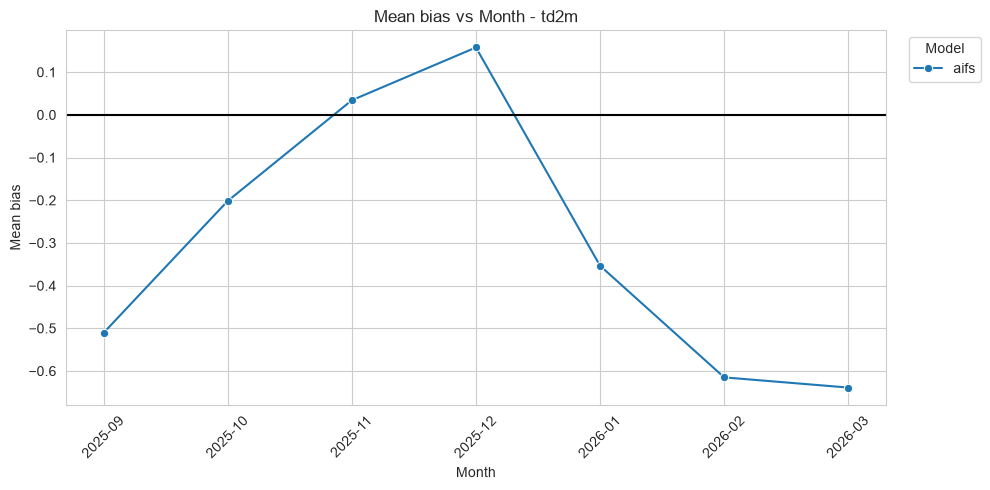

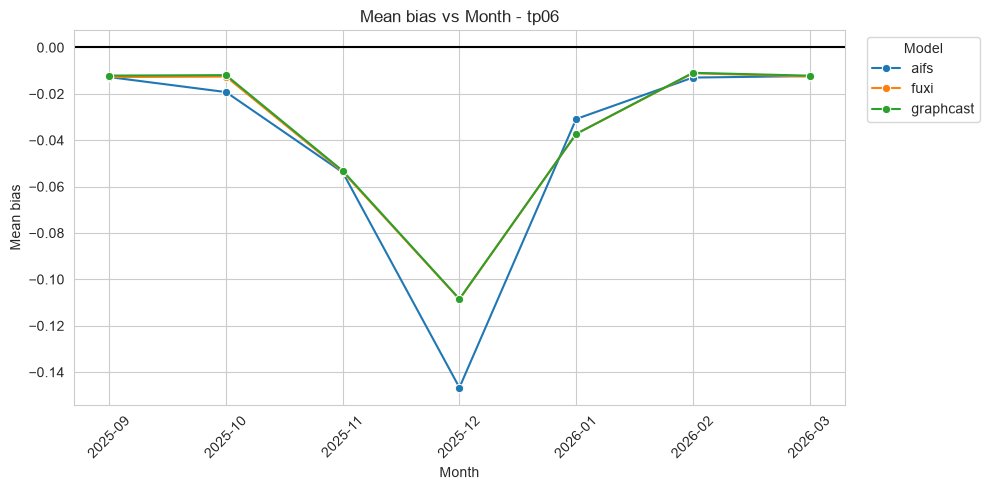

In [21]:
# Monthly bias plot, for every variable
for var in sorted(df['variable_name'].unique()):
    plot_bias_over_time(df_monthly, 'month', var, 'Month', f'monthly_bias_{var}.png')

The monthly bias shows if errors change between months. **GraphCast** has the largest **msl** bias in **January 2026** (**−6.1**). For **tp06**, the three models have the largest errors in **December 2025**, when rainfall is more common.

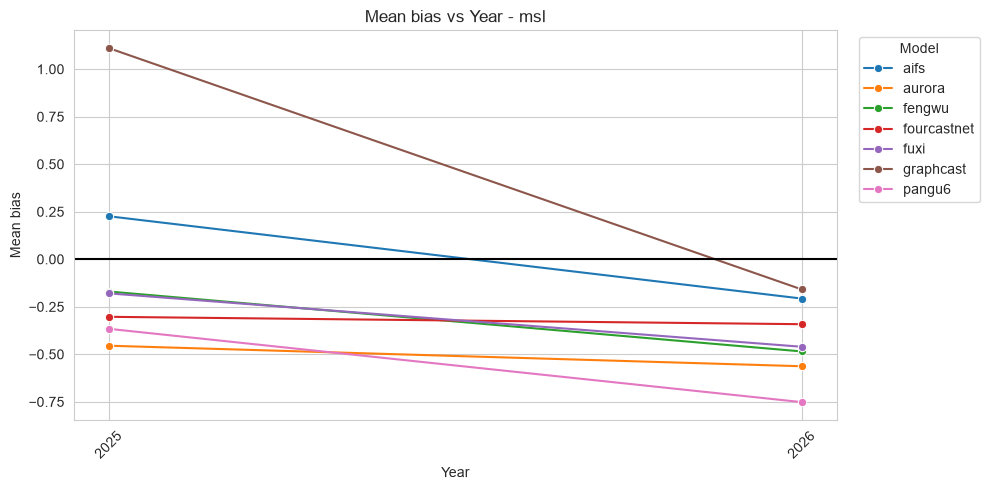

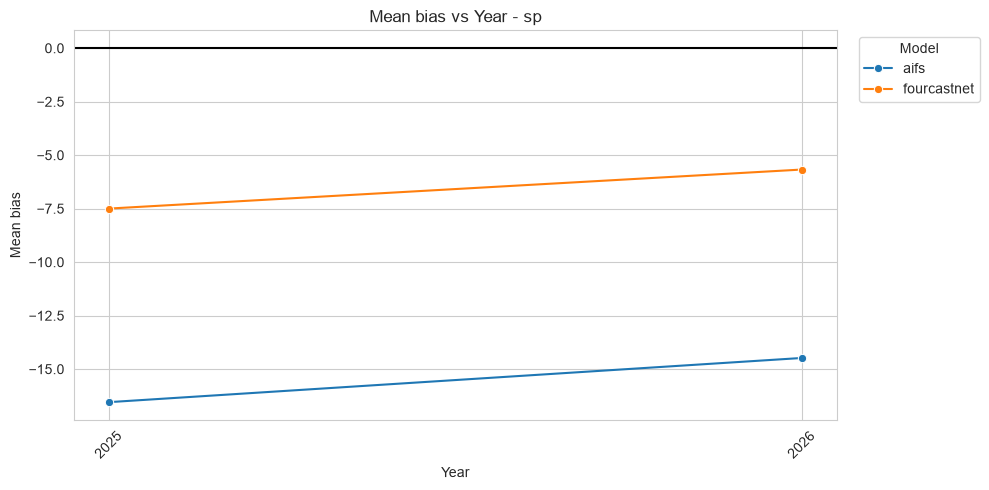

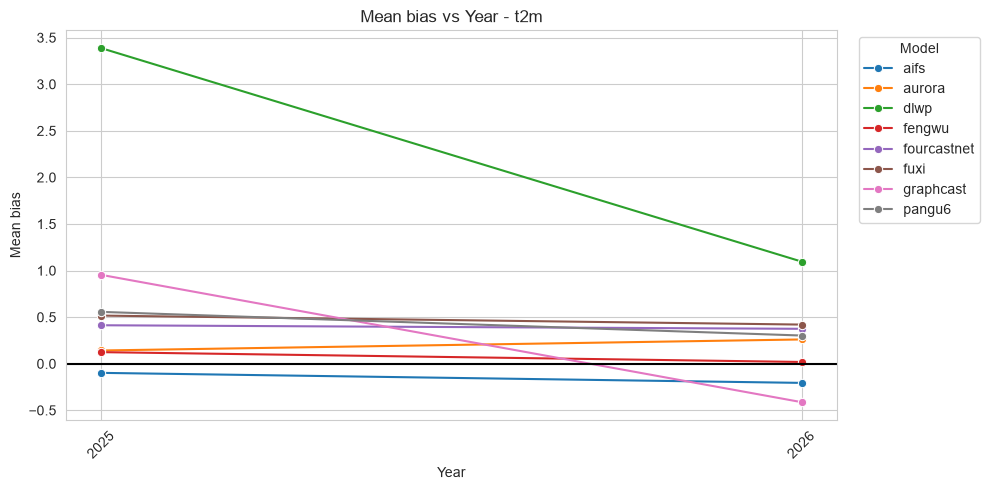

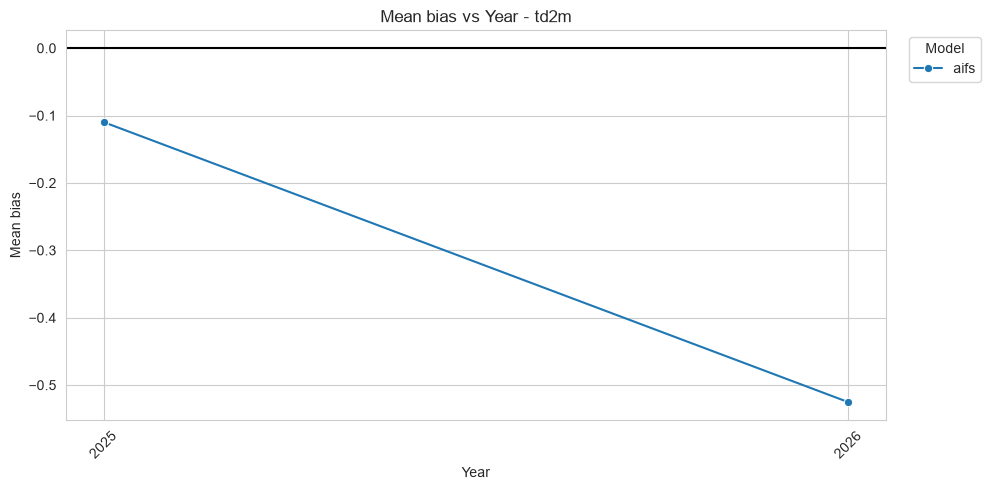

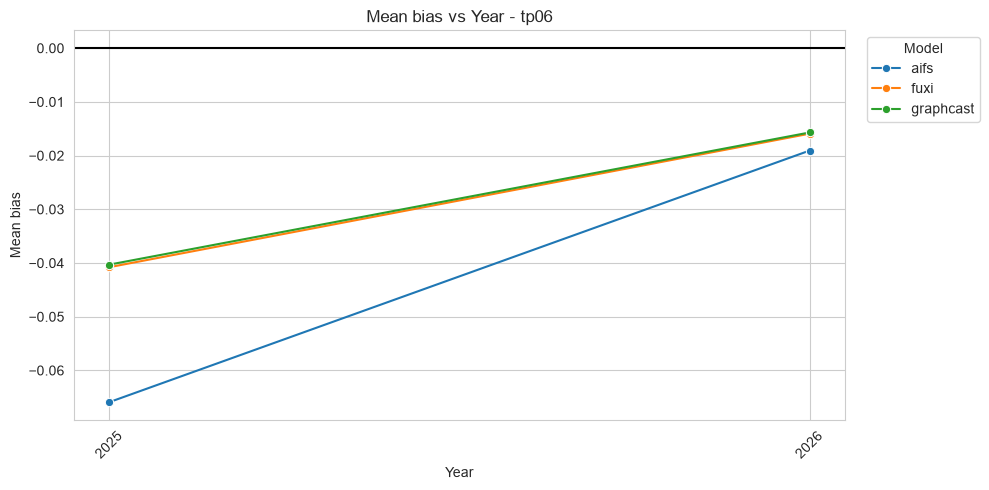

In [22]:
# Annual bias plot, for every variable
for var in sorted(df['variable_name'].unique()):
    plot_bias_over_time(df_annual, 'year', var, 'Year', f'annual_bias_{var}.png')

The yearly bias shows how model errors change between years. **DLWP** has a smaller **t2m** bias in **2026** than in **2025**. However, this may be caused by different data coverage, not better model performance.

## 6. Models Ranked by RMSE

No rain: 98.48%


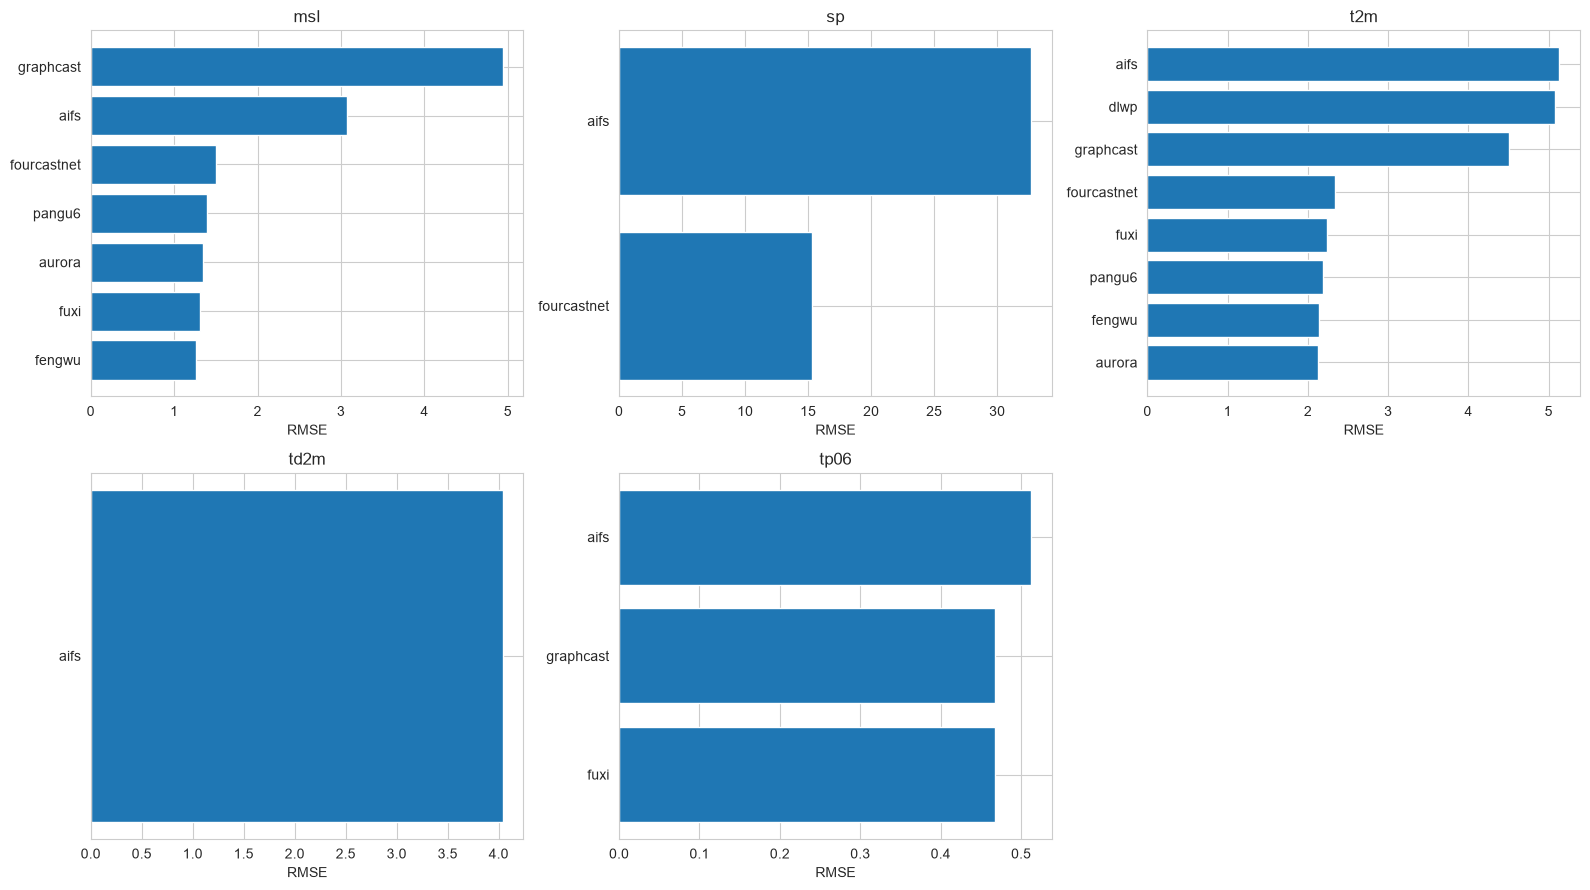

In [23]:
# Calculate the percentage of observations with no rainfall
df_tp06 = df[df["variable_name"] == "tp06"].copy()

no_rain = (df_tp06["obs_value"] == 0).sum()

percentage = no_rain / len(df_tp06) * 100

print(f"No rain: {percentage:.2f}%")

variables = sorted(df["variable_name"].unique())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

# Plot the RMSE ranking for each weather variable
for i, var in enumerate(variables):
    data = ( model_performance[model_performance["variable_name"] == var].sort_values("rmse"))

    axes[i].barh(data["model"], data["rmse"])
    axes[i].set_title(var)
    axes[i].set_xlabel("RMSE")

# Hide the unused subplot
for j in range(len(variables), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig("../results/figures/ranking_rmse_all_variables.png", dpi=300)
plt.show()

Ranking the models by RMSE shows which models perform best. For **t2m** and **msl**, five models have low errors, while two or three have much higher errors and need calibration. For **tp06**, the RMSE is similar for all models, but this is because **98%** of the observations have no rain.

## 6b. Bias vs lead time

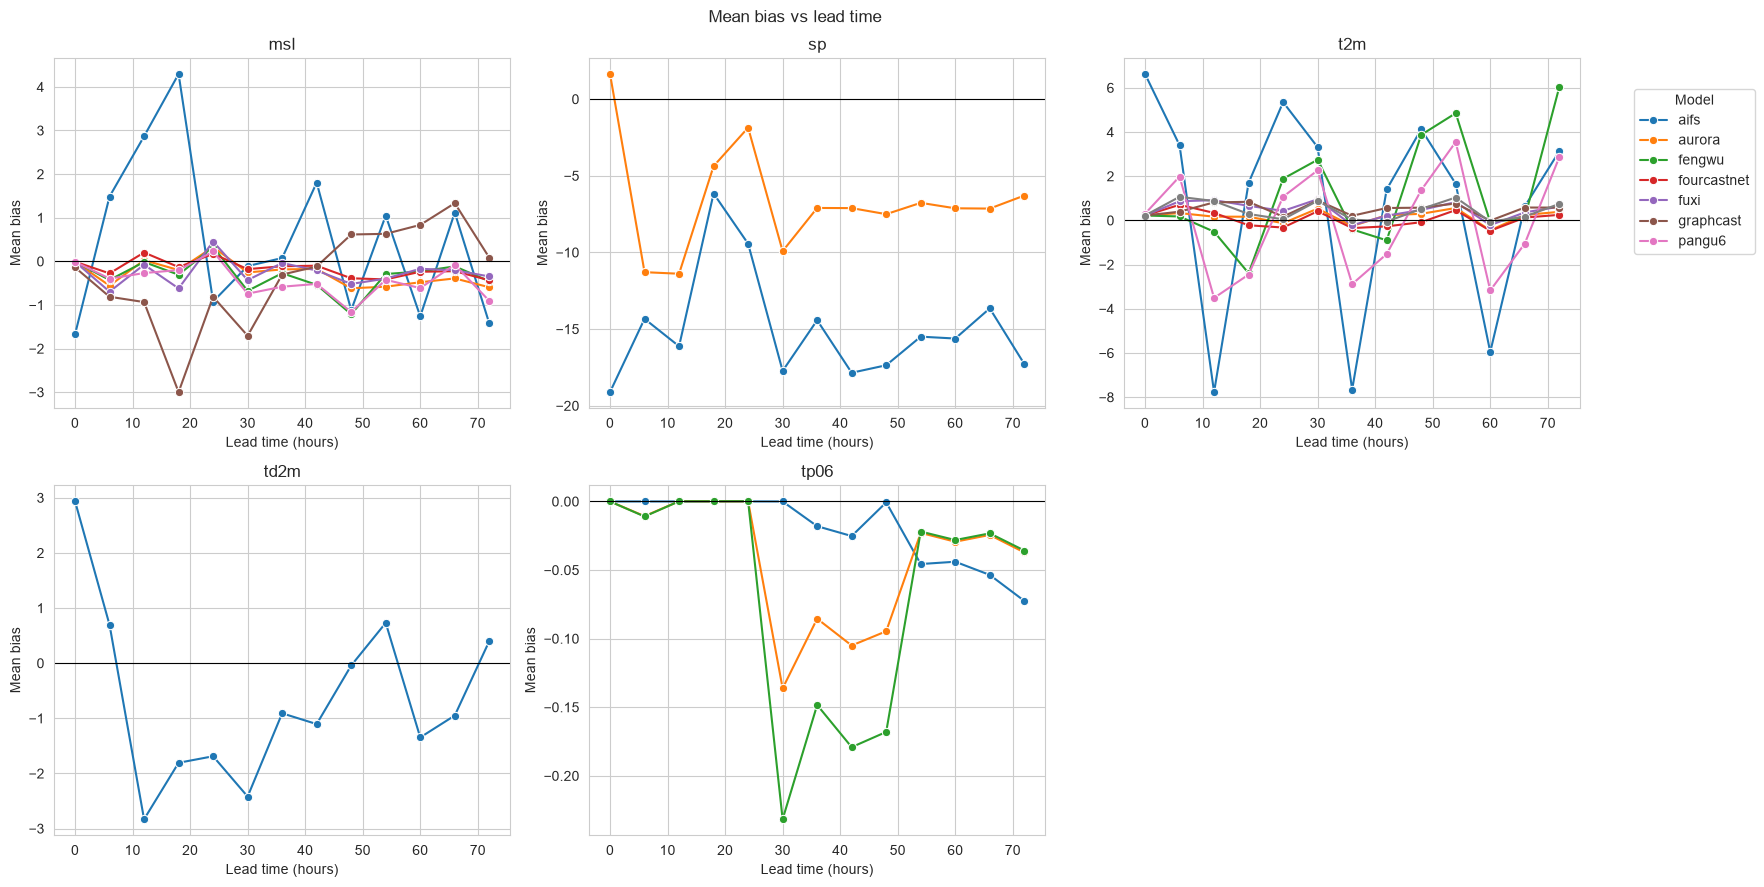

In [24]:
# Mean bias vs lead time
df_leadtime = df.groupby(['model', 'variable_name', 'lead_time'])['biais'].mean().reset_index()

variables = sorted(df_leadtime['variable_name'].unique())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, var in enumerate(variables):
    data = df_leadtime[df_leadtime['variable_name'] == var]

    sns.lineplot(data=data,x='lead_time',y='biais',hue='model',marker='o',ax=axes[i])

    axes[i].axhline(0, color='black', linewidth=0.8)
    axes[i].set_title(var)
    axes[i].set_xlabel('Lead time (hours)')
    axes[i].set_ylabel('Mean bias')
    axes[i].grid(True)
    axes[i].legend().remove()   # remove individual legends

# Hide the unused subplot
for j in range(len(variables), len(axes)):
    axes[j].axis('off')

# One shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Model',bbox_to_anchor=(1.02, 0.9), loc='upper left')

plt.suptitle('Mean bias vs lead time')
plt.tight_layout()
plt.savefig('../results/figures/bias_vs_leadtime_all_variables.png', bbox_inches='tight')
plt.show()

The lead time bias shows how errors change as the forecast gets longer. For most variables, the bias follows a **24-hour** pattern instead of increasing slowly. This is caused by the day–night cycle. Only **tp06** shows a gradual increase in error after **24 hours**.

## 7. Bias distribution per model (t2m)

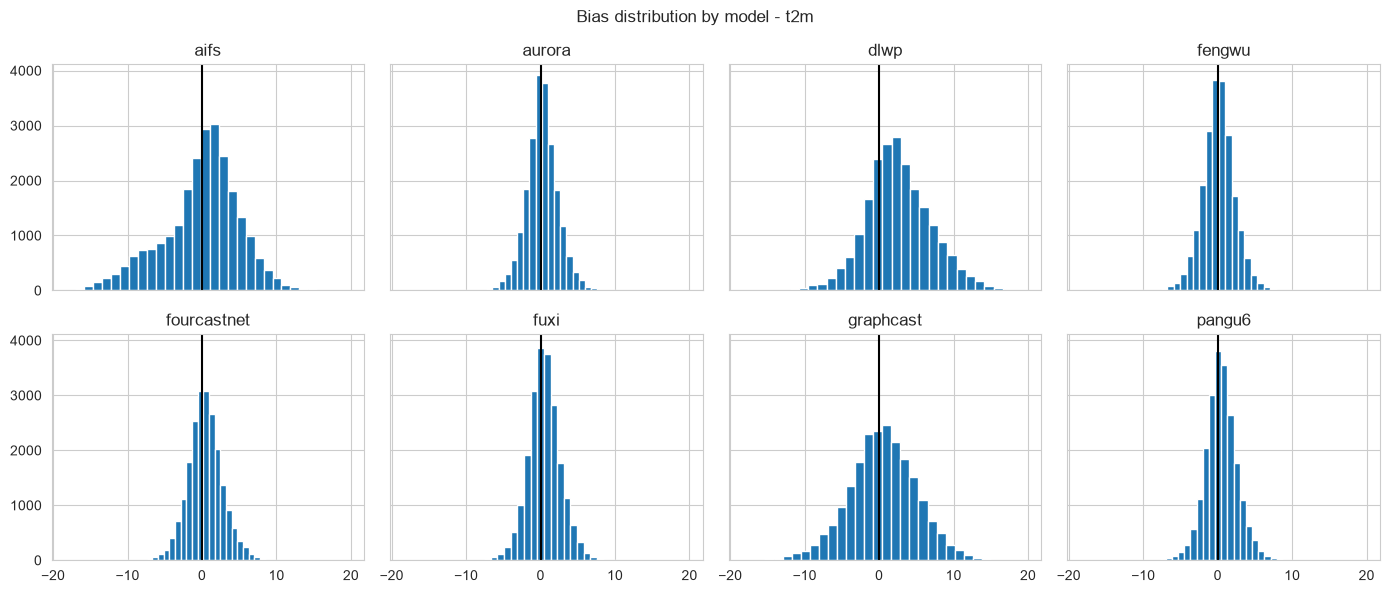

In [25]:
df_t2m = df[df['variable_name'] == 't2m']
models = sorted(df_t2m['model'].unique())

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
axes = axes.flatten()

for i, model in enumerate(models):
    data = df_t2m[df_t2m['model'] == model]
    axes[i].hist(data['biais'], bins=30)
    axes[i].axvline(0, color='black')
    axes[i].set_title(model)

plt.suptitle('Bias distribution by model - t2m')
plt.tight_layout()
plt.savefig('../results/figures/bias_distribution_t2m.png')
plt.show()

The temperature bias distribution shows the size and spread of errors. **Aurora** and **Fengwu** have small errors close to zero. **DLWP** usually overestimates temperature. **AIFS** and **GraphCast** have the largest error spread.

## 8. Predicted vs Observed (t2m)

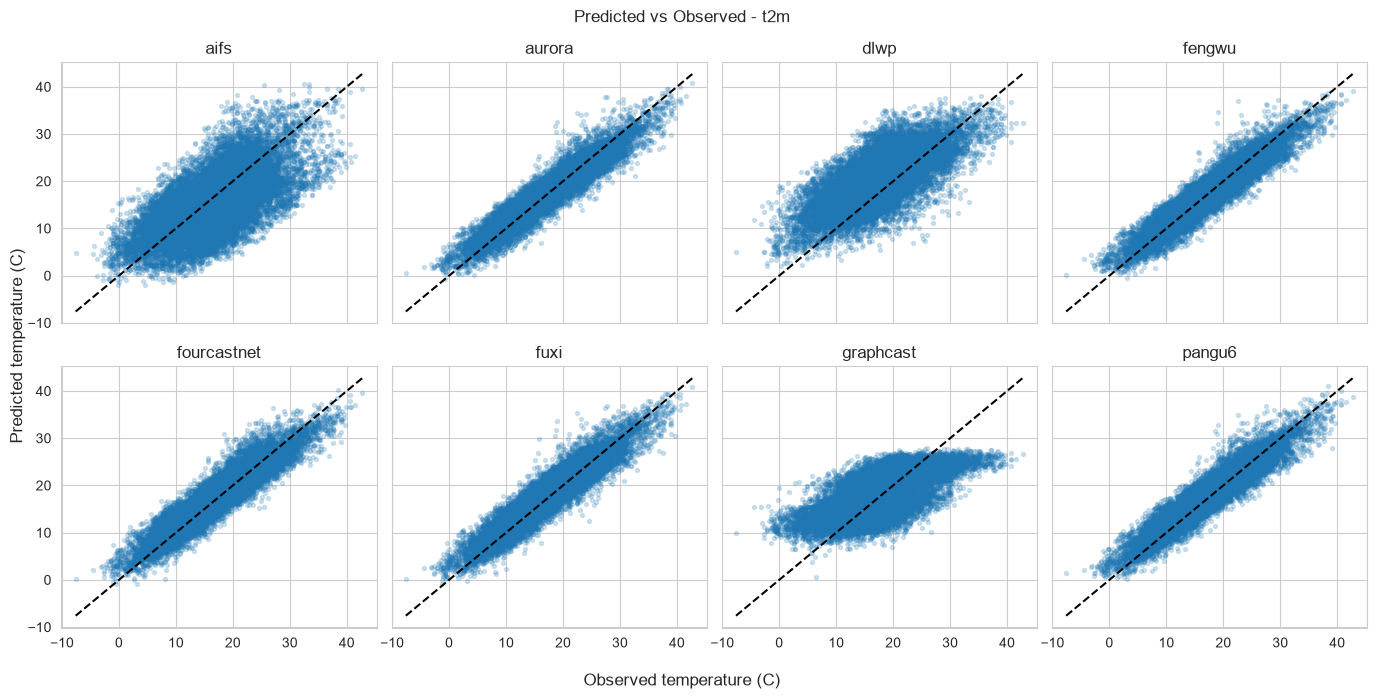

In [26]:
min_obs_temp = df_t2m['obs_value'].min()
max_obs_temp = df_t2m['obs_value'].max()

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)
axes = axes.flatten()

for i, model in enumerate(models):
    data = df_t2m[df_t2m['model'] == model]
    axes[i].scatter(data['obs_value'], data['pred_value'], alpha=0.2, s=8)
    axes[i].plot([min_obs_temp, max_obs_temp], [min_obs_temp, max_obs_temp], 'k--')# draw a black dashed line
    axes[i].set_title(model)

fig.supxlabel('Observed temperature (C)')
fig.supylabel('Predicted temperature (C)')
plt.suptitle('Predicted vs Observed - t2m')
plt.tight_layout()
plt.savefig('../results/figures/pred_vs_obs_t2m.png')
plt.show()

Comparing predicted and observed temperatures shows model accuracy. **Aurora, Fengwu, and Pangu6** are closest to the diagonal, while **AIFS** has the largest spread. **GraphCast** never predicts above **28°C**, even though the observed temperature reaches **42.7°C**.

## 9. Bias Across Observed Temperature Ranges

Split the observed temperature into 5°C ranges to check whether the models perform differently in cold and hot weather.

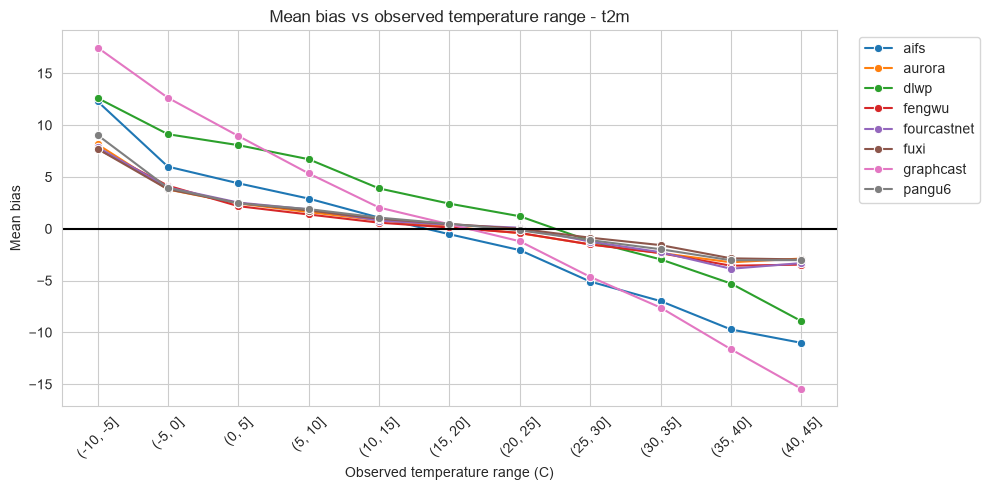

In [27]:
# Split the observed temperature into 5C ranges
df_t2m['obs_bin'] = pd.cut(df_t2m['obs_value'], bins=range(-10, 46, 5))

bin_bias = df_t2m.groupby(['model', 'obs_bin'], observed=True)['biais'].mean().reset_index()
bin_bias['obs_bin'] = bin_bias['obs_bin'].astype(str)

plt.figure(figsize=(10, 5))
sns.lineplot(data=bin_bias, x='obs_bin', y='biais', hue='model', marker='o')

plt.title('Mean bias vs observed temperature range - t2m')
plt.xlabel('Observed temperature range (C)')
plt.ylabel('Mean bias')
plt.xticks(rotation=45)
plt.axhline(0, color='black')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../results/figures/bias_vs_observed_temp_t2m.png')
plt.show()

The bias changes with the observed temperature. All **eight models** **overestimate** low temperatures and **underestimate** high temperatures. **GraphCast** has the largest bias and rarely predicts temperatures above **28°C**. The models are most accurate between **10°C** and **25°C**, where the bias is close to zero.

## 10. Bias by time of day (t2m)

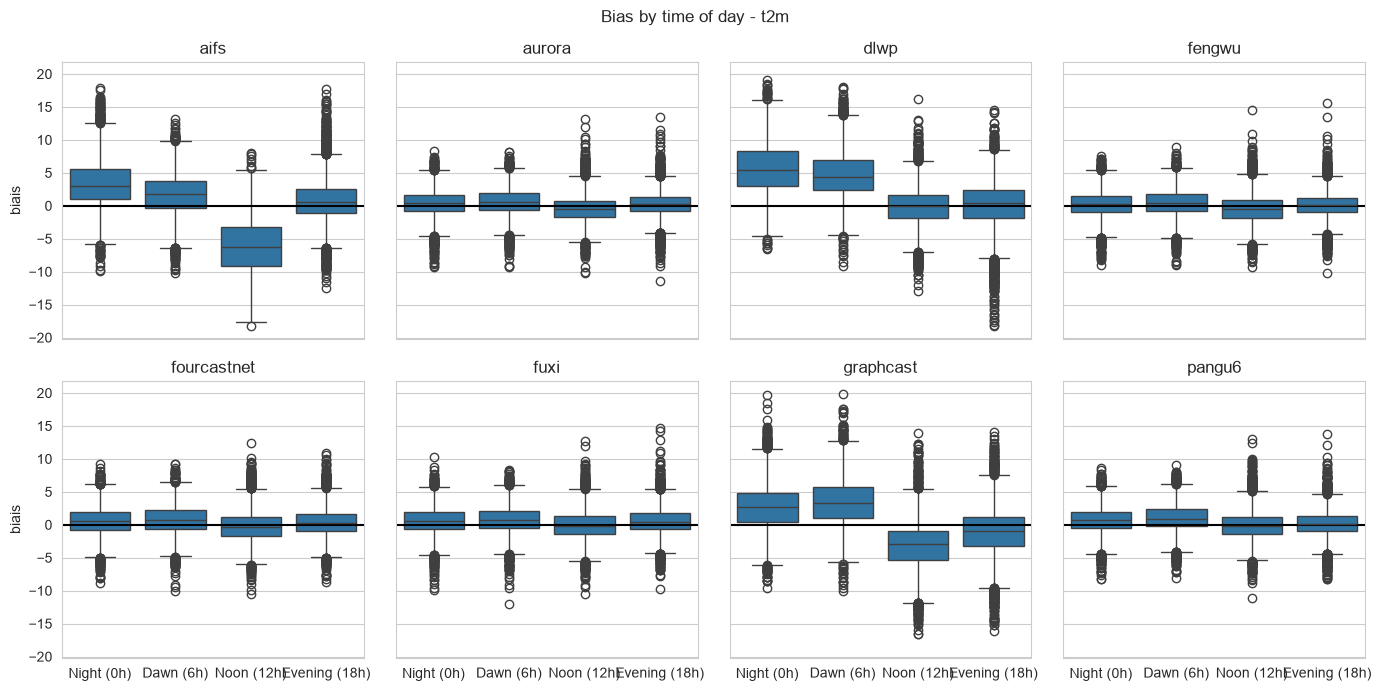

In [28]:
df['time_of_day'] = pd.cut(df['hour'], bins=[-1, 5, 11, 17, 23], labels=['Night (0h)', 'Dawn (6h)', 'Noon (12h)', 'Evening (18h)'])
df_t2m = df[df['variable_name'] == 't2m']

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)
axes = axes.flatten()
for i, model in enumerate(models):
    data = df_t2m[df_t2m['model'] == model]
    sns.boxplot(data=data, x='time_of_day', y='biais', ax=axes[i])
    axes[i].axhline(0, color='black')
    axes[i].set_title(model)
    axes[i].set_xlabel('')
plt.suptitle('Bias by time of day - t2m')
plt.tight_layout()
plt.savefig('../results/figures/bias_by_timeofday_t2m.png')
plt.show()

The bias changes during the day. **AIFS** has the largest negative bias at **Noon (-6.35°C)**. **DLWP** has the largest positive bias at **Night (+5.77°C)** and **Dawn (+4.69°C)**, but performs better at **Noon** and **Evening**.

## 11. Correlation between columns, one heatmap per variable

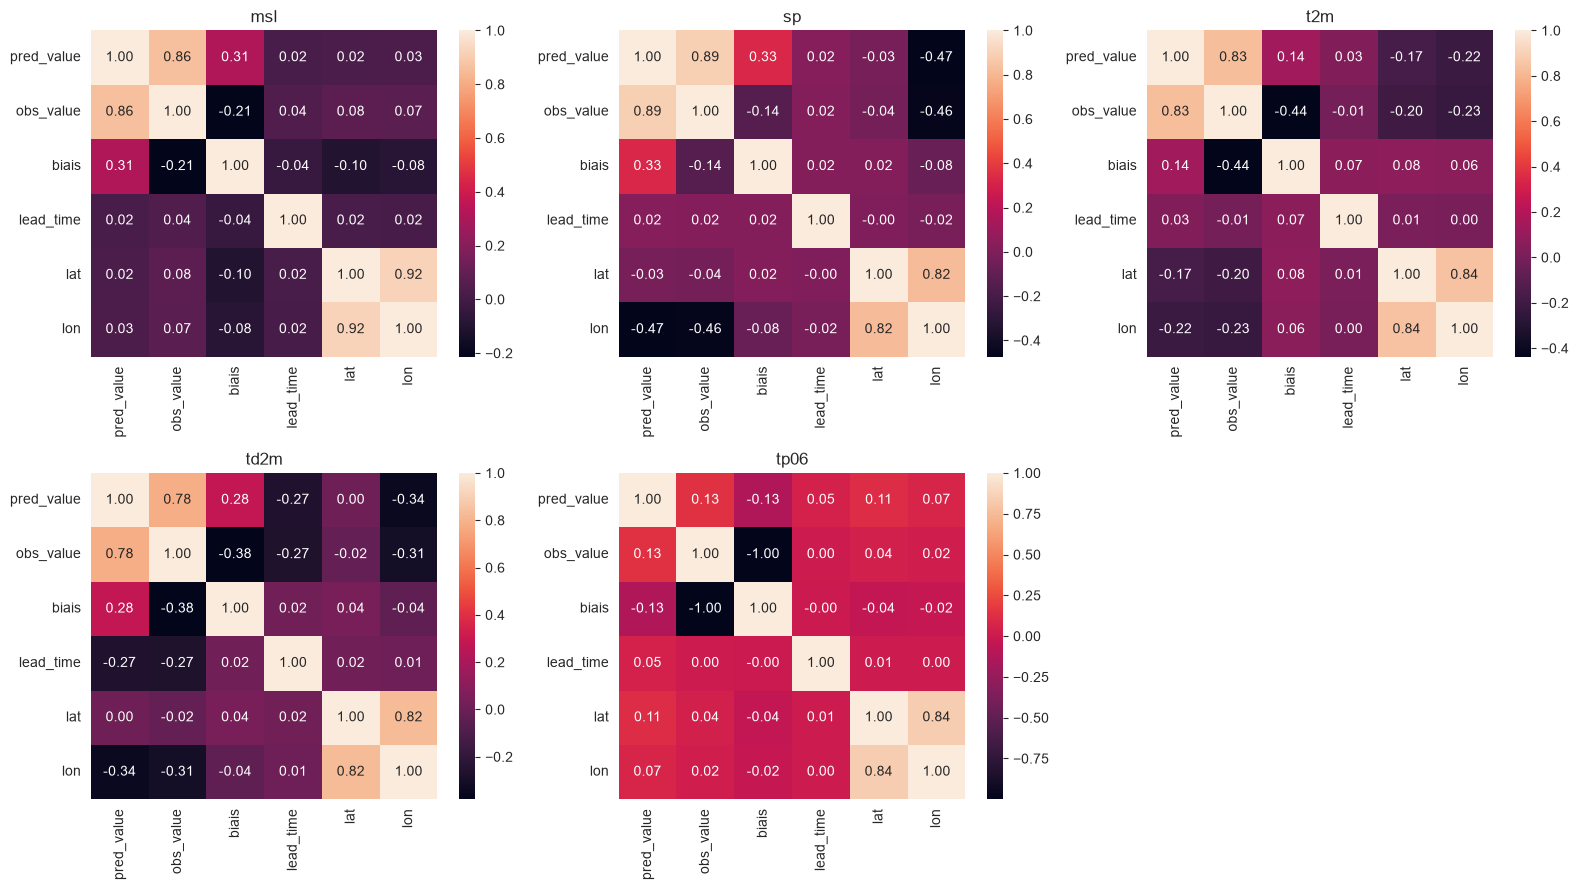

In [29]:
columns_to_check = ['pred_value', 'obs_value', 'biais', 'lead_time', 'lat', 'lon']
variables = sorted(df['variable_name'].unique())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, var in enumerate(variables):
    data = df[df['variable_name'] == var][columns_to_check]
    sns.heatmap(data.corr(), annot=True, fmt='.2f', ax=axes[i])
    axes[i].set_title(var)

for j in range(len(variables), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('../results/figures/correlation_per_variable.png')
plt.show()

The correlation shows how the variables are related. **msl, sp, t2m, and td2m** have a strong correlation (**0.78–0.89**) between predicted and observed values. **tp06** has a weak correlation (**0.13**), showing that rainfall is harder to predict. The **-1.00** correlation between observed rainfall and bias is not a real relationship. It happens because **bias = pred_value − obs_value**, and the predicted rainfall is almost always **0**, so **bias ≈ −obs_value**.

## 12. Check for precipitation (tp06)

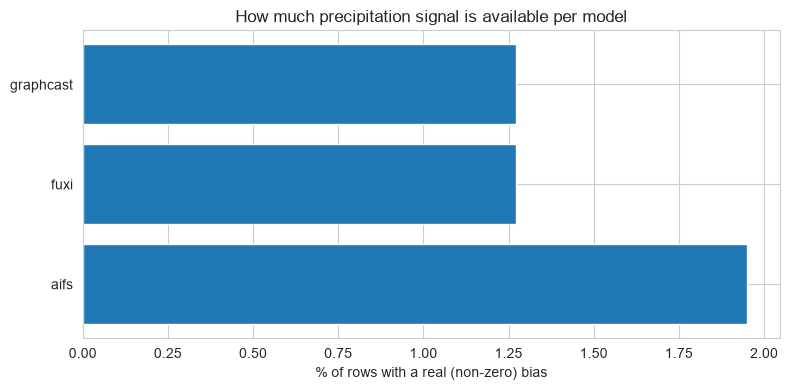

model
aifs         1.949367
fuxi         1.270782
graphcast    1.270782
Name: has_signal, dtype: float64


In [30]:
# A bias is "non-zero" if it is bigger than a small threshold (0.1 mm)
df_tp06['has_signal'] = df_tp06['biais'].abs() > 0.1

percent_signal = df_tp06.groupby('model')['has_signal'].mean() * 100
percent_signal = percent_signal.sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.barh(percent_signal.index, percent_signal.values)
plt.xlabel('% of rows with a real (non-zero) bias')
plt.title('How much precipitation signal is available per model')
plt.tight_layout()
plt.savefig('../results/figures/tp06_signal_per_model.png')
plt.show()

print(percent_signal)

More than **98%** of the **tp06** observations have no rainfall. Only about **1.3% to 2.0%** have a non-zero prediction error. This makes precipitation calibration much more difficult.

## 13. Bias by station (t2m)

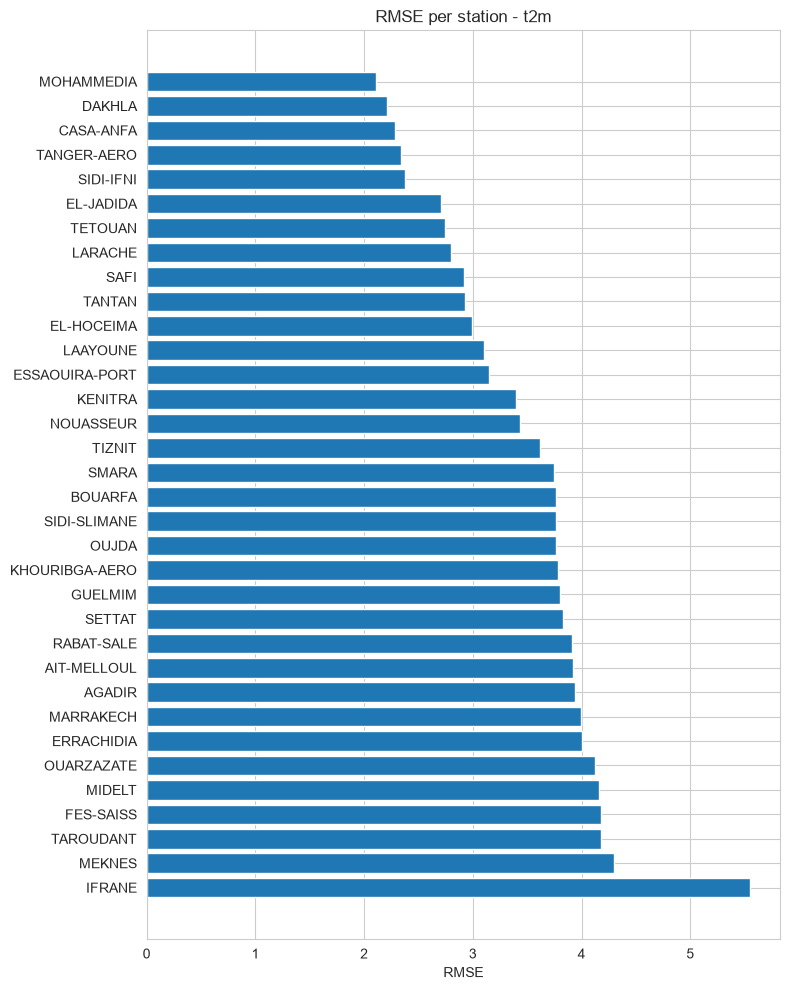

,mean_bias,rmse,n
station,,,
IFRANE,3.813022,5.547145,5515
MEKNES,1.424669,4.294435,5519
TAROUDANT,1.001303,4.179190,4527
FES-SAISS,1.213703,4.174485,5519
MIDELT,2.194206,4.156529,4527
OUARZAZATE,-1.322563,4.125899,4527
ERRACHIDIA,-0.063404,4.005253,4527
MARRAKECH,-1.572878,3.996892,5519
AGADIR,0.473008,3.935276,3364


In [31]:
df_t2m = df[df['variable_name'] == 't2m']

station_summary = df_t2m.groupby('station').agg(
    mean_bias=('biais', 'mean'),
    rmse=('erreur_sq', lambda x: np.sqrt(x.mean())),
    n=('biais', 'size')
).sort_values('rmse', ascending=False)

plt.figure(figsize=(8, 10))
plt.barh(station_summary.index, station_summary['rmse'])
plt.xlabel('RMSE')
plt.title('RMSE per station - t2m')
plt.tight_layout()
plt.savefig('../results/figures/rmse_per_station_t2m.png')
plt.show()

station_summary

The RMSE changes between weather stations. **IFRANE** has the highest RMSE (**5.55°C**), while **MOHAMMEDIA** has the lowest (**2.11°C**). In general, **mountain and inland stations** have larger errors than **coastal stations**. The bias also changes from one station to another.

## 14. Effect of Distance to the Grid Point on Forecast Bias (t2m)

Overall correlation between distance_km and abs(bias): 0.267
             mean_distance_km  mean_abs_bias  corr_distance_bias    n_obs
model                                                                    
aifs                39.393757       3.936235            0.036183  24611.0
dlwp                 9.371728       3.935608           -0.033142  21474.0
graphcast           40.014264       3.548572           -0.014571  21474.0
fourcastnet          9.371728       1.800564            0.010314  21474.0
fuxi                 9.371728       1.709059            0.030381  21474.0
pangu6               9.371728       1.667721            0.016209  21474.0
fengwu               9.371728       1.636800            0.057177  21474.0
aurora               9.371728       1.612378            0.066869  21474.0


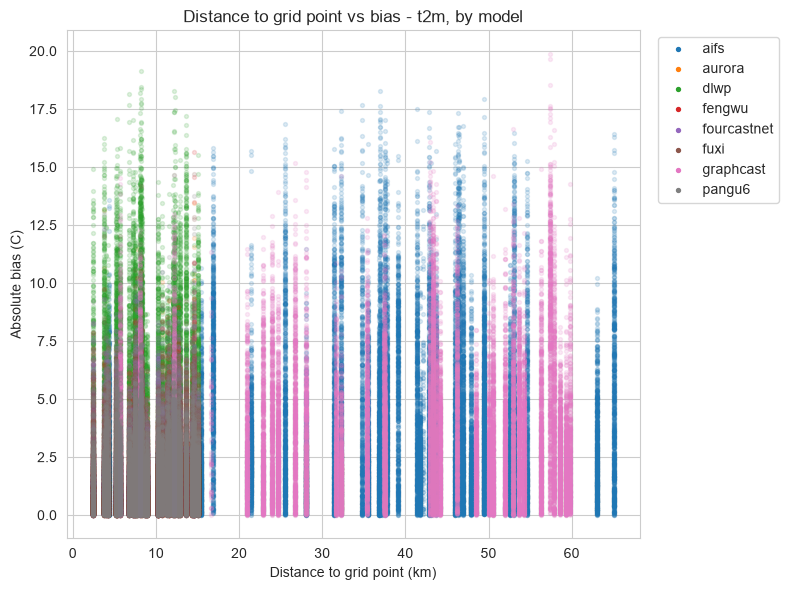

In [32]:
# Keep only temperature data
df_t2m = df[df['variable_name'] == 't2m'].copy()

# Calculate the absolute bias
df_t2m['abs_bias'] = df_t2m['biais'].abs()

# Calculate the overall correlation
overall_corr = df_t2m[['distance_km', 'abs_bias']].corr().iloc[0, 1]
print('Overall correlation between distance_km and abs(bias):', round(overall_corr, 3))

# Calculate the results for each model
per_model = df_t2m.groupby('model').apply(
    lambda g: pd.Series({
        'mean_distance_km': g['distance_km'].mean(),
        'mean_abs_bias': g['abs_bias'].mean(),
        'corr_distance_bias': g[['distance_km', 'abs_bias']].corr().iloc[0, 1],
        'n_obs': len(g)
    })
).sort_values('mean_abs_bias', ascending=False)
print(per_model)

# Plot distance to grid point vs absolute bias
plt.figure(figsize=(8, 6))
for m, g in df_t2m.groupby('model'):
    plt.scatter(g['distance_km'], g['abs_bias'], alpha=0.15, s=8, label=m)

# Keep legend markers fully visible
legend = plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
for lh in legend.legend_handles:
    lh.set_alpha(1)

plt.xlabel('Distance to grid point (km)')
plt.ylabel('Absolute bias (C)')
plt.title('Distance to grid point vs bias - t2m, by model')
plt.tight_layout()
plt.savefig('../results/figures/distance_vs_bias_t2m_by_model.png')
plt.show()

The overall correlation between **distance** and **absolute bias** is **0.267**. However, for each model, the correlation is close to **zero**, showing that **distance has little effect on prediction error**. This is because **six models** have a similar distance (**9.4 km**), while **AIFS** and **GraphCast** are farther away (**39–40 km**). **DLWP** also has a high bias despite its short distance. Overall, **model characteristics** have a bigger effect than **distance**.

## 15. Biggest errors (outliers)

In [33]:
df_t2m = df[df['variable_name'] == 't2m']
worst = df_t2m.loc[df_t2m['biais'].abs().sort_values(ascending=False).index]
worst[['model', 'station', 'valid_time', 'lead_time', 'pred_value', 'obs_value', 'biais']].head(10)

,model,station,valid_time,lead_time,pred_value,obs_value,biais
84059,graphcast,IFRANE,2025-12-05 06:00:00,54,15.391290,-4.5,19.891290
59702,graphcast,IFRANE,2025-11-09 00:00:00,72,19.548792,-0.1,19.648792
59572,dlwp,IFRANE,2025-11-09 00:00:00,72,19.018030,-0.1,19.118030
83503,graphcast,IFRANE,2025-12-05 00:00:00,72,15.336298,-3.2,18.536298
72368,dlwp,IFRANE,2025-11-23 00:00:00,72,18.637659,0.2,18.437659
86123,dlwp,IFRANE,2025-12-08 00:00:00,72,18.753198,0.4,18.353198
214927,aifs,MEKNES,2025-09-20 12:00:00,36,18.725190,37.0,-18.274810
117927,dlwp,OUARZAZATE,2026-02-19 18:00:00,66,7.340387,25.6,-18.259613
72363,dlwp,FES-SAISS,2025-11-23 00:00:00,72,21.983911,3.8,18.183911
118863,dlwp,SMARA,2026-02-20 18:00:00,66,13.254999,31.4,-18.145001


The largest prediction errors show cases that average metrics cannot. **6 of the 10** largest temperature errors occur at **IFRANE**, making it the most difficult station to predict. The errors include both large overestimates and underestimates. For example, in **Meknes**, the model predicted **18.7°C**, while the observed temperature was **37.0°C**.

## 16. Statistical Validation of the Time-of-Day Effect on Bias

In [34]:
df_t2m = df[df['variable_name'] == 't2m']

for model in sorted(df_t2m['model'].unique()):
    data = df_t2m[df_t2m['model'] == model]
    groups = [g['biais'].values for _, g in data.groupby('time_of_day', observed=True)]
    f_stat, p_value = f_oneway(*groups)
    print(f'{model:11}: F = {f_stat:8.1f}, p = {p_value:.4f}')

aifs       : F =   9071.9, p = 0.0000
aurora     : F =    224.9, p = 0.0000
dlwp       : F =   4159.9, p = 0.0000
fengwu     : F =    183.7, p = 0.0000
fourcastnet: F =    203.5, p = 0.0000
fuxi       : F =    120.8, p = 0.0000
graphcast  : F =   4211.7, p = 0.0000
pangu6     : F =    297.3, p = 0.0000


The ANOVA test shows that the **time of day** has a significant effect on the prediction bias for **all eight models** (**p-value ≈ 0.0000**). **AIFS (F = 9072)**, **GraphCast (F = 4212)**, and **DLWP (F = 4160)** have much larger F-values than the other models. These models also have the highest RMSE, showing that the **time of day** is an important source of their prediction errors.

## 17. Features that explain the bias the most
Estimates which features (lead time, hour, month, station, latitude, longitude)
carry the most information about the bias, before building the calibration model.

             aifs  aurora    dlwp  fengwu  fourcastnet    fuxi  graphcast  \
lead_time  0.3702  0.0267  0.2725  0.0167       0.0233  0.0147     0.2544   
hour       0.3592  0.0260  0.2508  0.0169       0.0232  0.0114     0.2487   
month      0.0245  0.0145  0.0574  0.0153       0.0137  0.0080     0.0425   
station    0.1406  0.1867  0.1409  0.1975       0.1553  0.2184     0.1575   
lat        0.0520  0.1273  0.1132  0.1411       0.1207  0.1586     0.0704   
lon        0.0506  0.1333  0.1064  0.1512       0.1186  0.1630     0.0705   

           pangu6  
lead_time  0.0288  
hour       0.0287  
month      0.0126  
station    0.1542  
lat        0.1209  
lon        0.1197  


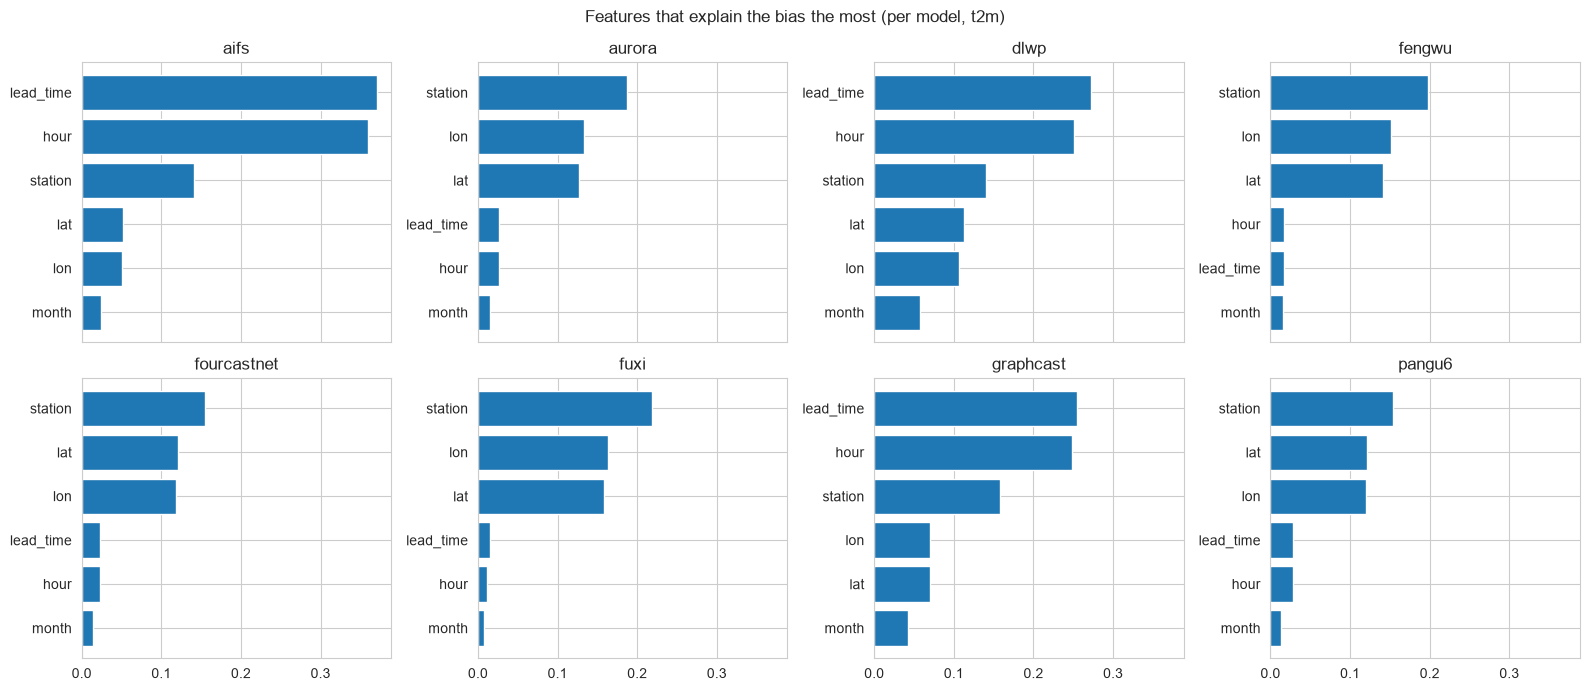

In [35]:
# Check each model separately
mi_per_model = {}

for model in sorted(df_t2m['model'].unique()):
    data = df_t2m[df_t2m['model'] == model]
    station_encoded_m = LabelEncoder().fit_transform(data['station'])

    features_m = pd.DataFrame({
        'lead_time': data['lead_time'],
        'hour': data['hour'],
        'month': data['month'],
        'station': station_encoded_m,
        'lat': data['lat'],
        'lon': data['lon'],
    })

    mi_scores_m = mutual_info_regression(features_m, data['biais'],discrete_features=[False, True, True, True, False, False],random_state=42)
    mi_per_model[model] = pd.Series(mi_scores_m, index=features_m.columns)

mi_per_model_df = pd.DataFrame(mi_per_model).round(4)
mi_per_model_df.to_csv(os.path.join('../results/tables','feature_importance_per_model_t2m.csv'),index=False)
print(mi_per_model_df)

# Plot: one bar chart per model, mutual information scores
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
axes = axes.flatten()
for i, model in enumerate(mi_per_model_df.columns):
    scores = mi_per_model_df[model].sort_values(ascending=True)
    axes[i].barh(scores.index, scores.values)
    axes[i].set_title(model)
plt.suptitle('Features that explain the bias the most (per model, t2m)')
plt.tight_layout()
plt.savefig('../results/figures/feature_importance_per_model_t2m.png')
plt.show()

The most important features are different for each model. For **AIFS, DLWP, and GraphCast**, **lead_time** and **hour** are the most important features. For **Aurora, Fengwu, FourCastNet, Fuxi, and Pangu6**, **station**, **latitude**, and **longitude** are the most important. This shows that some models are affected more by **time**, while others are affected more by **location**.

## 18. Hour Encoding

The **hour of the day affects the bias**, but using it directly (0, 6, 12, 18) is not ideal because time is circular. For example, **18:00 and 00:00** are close in time but have very different values.

To solve this, we use **`hour_sin`** and **`hour_cos`** to represent the circular nature of time. We also add **`is_afternoon`** and **`is_night`** based on the bias patterns found in the data.

- **Hour 0 and 6** have similar bias behavior, so they are grouped as `is_night`.
- **Hour 12** shows a different bias pattern, so it is marked as `is_afternoon`.
- **Hour 18** is not added as a separate feature because its bias behavior is closer to the normal range and does not represent a clear separate bias regime.

These four features are added to `df` and reused later for calibration.

In [36]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["is_afternoon"] = (df["hour"] == 12).astype(int)
df["is_night"] = df["hour"].isin([0, 6]).astype(int)

df[["hour", "hour_sin", "hour_cos", "is_afternoon", "is_night"]].drop_duplicates().sort_values("hour")


,hour,hour_sin,hour_cos,is_afternoon,is_night
0,0,0.000000e+00,1.000000e+00,0,1
31,6,1.000000e+00,6.123234e-17,0,1
64,12,1.224647e-16,-1.000000e+00,1,0
97,18,-1.000000e+00,-1.836970e-16,0,0


## Conclusion

The analysis shows that the **hour of the day is one of the main factors affecting forecast bias**, with all models showing a clear daily cycle that is often stronger than the effect of forecast horizon. The performance of the AI weather models also differs significantly: **Aurora, Fengwu, Pangu6, Fuxi,** and **FourCastNet** provide the most accurate temperature forecasts, while **AIFS, DLWP,** and **GraphCast** show larger errors and have the highest potential for calibration.

The bias also depends on both **temperature range** and **location**. Models tend to overestimate cold temperatures and underestimate hot temperatures, while some stations such as **IFRANE** are more difficult to predict. The analysis of grid-point distance shows that it has little influence on prediction errors, meaning that differences are mainly related to the model characteristics rather than the station-grid distance.

Finally, **precipitation (`tp06`) remains the most challenging variable to calibrate** because rainfall events are rare in the dataset. Based on these findings, new time-based features (**`hour_sin`, `hour_cos`, `is_night`, and `is_afternoon`**) were created to capture the daily bias patterns and will be used in the calibration models presented in Part 2.

# Part 2: Bias Calibration Models

**Bias calibration** aims to correct the errors made by AI weather models. The bias is defined as:

`bias = predicted value - observed value`

A calibration model learns to predict this bias, which is then used to correct the original forecast:

`corrected forecast = predicted value - predicted bias`

**The following models are used:**

- **MLP (Multi-Layer Perceptron):** a neural network that learns complex relationships between features and bias.
- **SVR (Support Vector Regression):** a regression model that uses kernels to capture nonlinear patterns.
- **Random Forest:** an ensemble of decision trees that improves stability and reduces overfitting.
- **LightGBM:** a boosting algorithm that builds trees sequentially to correct previous errors.

**Two configurations are tested:**

- **Config A (single variable):** uses only the predicted value of the target variable.
- **Config B (multi-parameter):** uses the target variable prediction together with other predicted weather variables.

This gives a total of **8 calibration models**:
- MLP (Config A and B)
- SVR (Config A and B)
- Random Forest (Config A and B)
- LightGBM (Config A and B)

## Step 1: Import the tools we need

In [37]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.svm import SVR, SVC
from lightgbm import LGBMRegressor, LGBMClassifier
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score , precision_score, recall_score, f1_score

sns.set_style("whitegrid")

## Step 2: Reuse the data from Part 1

We already loaded and cleaned the data in Part 1: AROME is removed, and `hour`, `month`,
`hour_sin`, `hour_cos`, `is_afternoon`, `is_night` are already added to `df`. We reuse the same
`df` table here instead of reading the file again.


## Step 3: Build the final feature columns

The required features are already available in `df` from Part 1. We select the columns that will be used as inputs for the calibration models.

The final features are:

- `pred_value`: the original forecast value from the AI weather model.
- `lat`, `lon`: station location, which can affect the bias.
- `lead_time`: forecast horizon, since longer forecasts can have larger errors.
- `hour_sin`, `hour_cos`: circular representation of the hour of the day.
- `is_afternoon`, `is_night`: time-of-day indicators based on the observed bias patterns.

In [38]:
# Keep features without pred_value because it changes name in Config B

BASE_FEATURES = ["lat", "lon", "lead_time", "hour_sin", "hour_cos", "is_afternoon", "is_night"]
FEATURES = ["pred_value"] + BASE_FEATURES

print("Feature columns:", FEATURES)
df[FEATURES + ["biais"]].head()

Feature columns: ['pred_value', 'lat', 'lon', 'lead_time', 'hour_sin', 'hour_cos', 'is_afternoon', 'is_night']


,pred_value,lat,lon,lead_time,hour_sin,hour_cos,is_afternoon,is_night,biais
0,20.277063,27.25,-13.25,0,0.0,1.0,0,1,-1.522937
1,19.077051,29.25,-10.25,0,0.0,1.0,0,1,-0.522949
2,22.777063,35.75,-6.00,0,0.0,1.0,0,1,-0.522937
3,21.477045,35.25,-6.00,0,0.0,1.0,0,1,-1.022955
4,21.877039,35.25,-3.75,0,0.0,1.0,0,1,2.577039


## Step 4: Split the data into train and test (by time)

The data is split based on time without shuffling.

- **Train set:** the first 80% of observations (older dates).
- **Test set:** the last 20% of observations (newer dates).

This avoids using future information during training. In real forecasting, the model only has access to past data, so a random split would give unrealistic results.

In [39]:
def split_train_test(table, test_fraction=0.2):

    table = table.sort_values("valid_time")
    n_rows = len(table)
    n_train = int(n_rows * (1 - test_fraction))
    train_part = table.iloc[:n_train].copy()
    test_part = table.iloc[n_train:].copy()
    return train_part, test_part


def get_scores(real_values, predicted_values):

    mae = mean_absolute_error(real_values, predicted_values)
    rmse = np.sqrt(mean_squared_error(real_values, predicted_values))
    r2 = r2_score(real_values, predicted_values)
    return {
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "R2": round(r2, 3),
    }

#Compare the raw and corrected forecasts on the test set; returns the scores and the improvement
def compare_to_baseline(test_table, predicted_bias, pred_column="pred_value"):

    real_obs = test_table["obs_value"]

    raw_forecast = test_table[pred_column]
    corrected_forecast = test_table[pred_column] - predicted_bias

    raw_mae = mean_absolute_error(real_obs, raw_forecast)
    raw_rmse = np.sqrt(mean_squared_error(real_obs, raw_forecast))

    corrected_mae = mean_absolute_error(real_obs, corrected_forecast)
    corrected_rmse = np.sqrt(mean_squared_error(real_obs, corrected_forecast))

    rmse_improvement_pct = (1 - corrected_rmse / raw_rmse) * 100 if raw_rmse > 0 else np.nan
    mae_improvement_pct = (1 - corrected_mae / raw_mae) * 100 if raw_mae > 0 else np.nan

    return {
        "raw_MAE": round(raw_mae, 3),
        "raw_RMSE": round(raw_rmse, 3),
        "corrected_MAE": round(corrected_mae, 3),
        "corrected_RMSE": round(corrected_rmse, 3),
        "RMSE_improvement_pct": round(rmse_improvement_pct, 1),
        "MAE_improvement_pct": round(mae_improvement_pct, 1),
    }


## Step 5: A table to store all results

Save each experiment result in a list.
At the end, convert the list into a table and save it as a CSV file.

In [40]:
all_results = []

def save_result(algorithm, config, weather_model, variable, scores, n_train, n_test,baseline_scores=None):
    row = {
        "algorithm": algorithm,
        "config": config,
        "weather_model": weather_model,
        "variable": variable,
        "n_train": n_train,
        "n_test": n_test,
    }
    row.update(scores)

    if baseline_scores is not None:
        row.update(baseline_scores)

    all_results.append(row)
    print(
        f"{algorithm:<15} ({config:<6}) | "
        f"MAE: {row['MAE']:.3f} | "
        f"RMSE: {row['RMSE']:.3f} | "
        f"R²: {row['R2']:.3f}"
    )


## Step 6: Config A - Single Variable

In Config A, the model uses the predicted value of the target variable (`t2m`) as the main input, together with non-meteorological features: station location, lead time, and time features.

Although the original definition of single-variable calibration uses only the predicted target variable, these additional features were added because the EDA showed that bias is also affected by **location**, **forecast horizon**, and **time of day**. They allow the model to learn these known bias patterns without using other predicted weather variables.

The target to predict is the forecast bias. This configuration is trained for **t2m** separately for each of the **8 AI weather models**.

## Hyperparameter Tuning Procedure for Config A

The hyperparameters used in this notebook were selected in `hyperparameter_tuning.ipynb`.

Each algorithm was tuned using **Optuna**, which searches automatically for good hyperparameter values based on previous trials. A **3-fold TimeSeriesSplit** was used during tuning to keep the time order of the data and avoid data leakage.

The tuning was performed on **AIFS/t2m**, which has the largest amount of data. The selected hyperparameters were then tested on **DLWP**, **GraphCast**, and **Fengwu** to check if they generalize to other models.

| Algorithm | Selected hyperparameters |
|---|---|
| MLP | `hidden_layer_sizes=(64,32)`, `activation="tanh"`, `alpha=0.000292`, `learning_rate_init=0.000817` |
| SVR | `kernel="rbf"`, `C=0.297`, `epsilon=0.483`, `gamma=0.0785` |
| Random Forest | `n_estimators=179`, `max_depth=22`, `min_samples_split=5`, `min_samples_leaf=10`, `max_features=0.360`, `max_samples=0.602` |
| LightGBM | `n_estimators=250`, `max_depth=12`, `learning_rate=0.0115`, `num_leaves=88`, `subsample=0.675`, `min_child_samples=60`, `colsample_bytree=0.753`, `reg_alpha=0.0033`, `reg_lambda=0.0061` |

### Generalization to other AI models

The tuned models were compared with their default versions on **DLWP**, **GraphCast**, and **Fengwu**.

| Algorithm | DLWP | GraphCast | Fengwu |
|---|---:|---:|---:|
| MLP | +1.3% | +1.1% | +1.4% |
| SVR | −1.4% | +0.8% | −2.8% |
| Random Forest | **+11.2%** | **+9.2%** | **+10.4%** |
| LightGBM | −0.5% | −0.3% | +1.0% |

The results show that **Random Forest generalizes the best**, improving RMSE by around **9–11%** on all tested models. **MLP** also provides small but consistent improvements. **SVR** and **LightGBM** show mixed results, with improvements on some models and small decreases on others.

These results highlight the importance of testing hyperparameters on different models, because good performance during tuning does not always guarantee good generalization.

In [41]:
def train_mlp_single(weather_model, variable):

    subset = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    train, test = split_train_test(subset)

    # Neural networks need scaled features because they are sensitive to feature ranges.
    # StandardScaler transforms each feature to have mean 0 and standard deviation 1.
    x_scaler = StandardScaler().fit(train[FEATURES])
    y_scaler = StandardScaler().fit(train[["biais"]])

    x_train = x_scaler.transform(train[FEATURES])
    y_train = y_scaler.transform(train[["biais"]]).ravel()
    x_test = x_scaler.transform(test[FEATURES])

    model = MLPRegressor(hidden_layer_sizes=(64, 32), activation="tanh", alpha=0.0002920433847181409,learning_rate_init=0.000816845589476017, max_iter=300, early_stopping=True, random_state=42)

    model.fit(x_train, y_train)

    predictions_scaled = model.predict(x_test)
    predictions = y_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).ravel()

    scores = get_scores(test["biais"], predictions)

    baseline_scores = compare_to_baseline(test, predictions)

    save_result("MLP", "single", weather_model, variable, scores, len(train), len(test), baseline_scores)

    return model


def train_svr_single(weather_model, variable):
    # SVR needs scaled features because it relies on distances between data points.
    # Large-scale features could dominate and affect the model results.

    subset = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    train, test = split_train_test(subset)

    x_scaler = StandardScaler().fit(train[FEATURES])
    y_scaler = StandardScaler().fit(train[["biais"]])

    x_train = x_scaler.transform(train[FEATURES])
    y_train = y_scaler.transform(train[["biais"]]).ravel()
    x_test = x_scaler.transform(test[FEATURES])

    model = SVR(kernel="rbf", C=0.29663272054469436, epsilon=0.48277125473350574, gamma=0.07848845094209282)
    model.fit(x_train, y_train)

    predictions_scaled = model.predict(x_test)
    predictions = y_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).ravel()

    scores = get_scores(test["biais"], predictions)

    baseline_scores = compare_to_baseline(test, predictions)

    save_result("SVR", "single", weather_model, variable, scores, len(train), len(test), baseline_scores)

    return model

# Random Forest and LightGBM are both tree-based, so they do not need scaled features

def train_random_forest_single(weather_model, variable):

    subset = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    train, test = split_train_test(subset)

    model = RandomForestRegressor(n_estimators=179, max_depth=22, min_samples_split=5,min_samples_leaf=10, max_features=0.36036833842338895, max_samples=0.6018991761512245,random_state=42, n_jobs=-1)

    model.fit(train[FEATURES], train["biais"])

    predictions = model.predict(test[FEATURES])

    scores = get_scores(test["biais"], predictions)

    baseline_scores = compare_to_baseline(test, predictions)

    save_result("RandomForest", "single", weather_model, variable, scores, len(train), len(test), baseline_scores)

    return model


def train_lgbm_single(weather_model, variable):
    # LightGBM uses boosting: each new tree learns from the previous errors to improve predictions

    subset = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    train, test = split_train_test(subset)

    model = LGBMRegressor(n_estimators=250, max_depth=12, learning_rate=0.011451844802259338, num_leaves=88,subsample=0.6745275586556285, min_child_samples=60, colsample_bytree=0.75261120564501,reg_alpha=0.003295732159059646, reg_lambda=0.0060924058597702615, random_state=42, n_jobs=-1, verbosity=-1)

    model.fit(train[FEATURES], train["biais"])

    predictions = model.predict(test[FEATURES])

    scores = get_scores(test["biais"], predictions)

    baseline_scores = compare_to_baseline(test, predictions)

    save_result("LGBM", "single", weather_model, variable, scores, len(train), len(test), baseline_scores)

    return model


In [42]:
ai_models = sorted(df[df["variable_name"] == "t2m"]["model"].unique())
print("We train on these AI models:", ai_models,end="\n")

# Store trained models to analyze feature importance later
rf_single_models = {}
lgbm_single_models = {}

print("\n**********************************************************\n")
for weather_model in ai_models:
    print(f"{weather_model}")

    train_mlp_single(weather_model, "t2m")
    train_svr_single(weather_model, "t2m")

    rf_single_models[weather_model] = train_random_forest_single(weather_model, "t2m")

    lgbm_single_models[weather_model] = train_lgbm_single(weather_model, "t2m")

    print("\n**********************************************************\n")


We train on these AI models: ['aifs', 'aurora', 'dlwp', 'fengwu', 'fourcastnet', 'fuxi', 'graphcast', 'pangu6']

**********************************************************

aifs
MLP             (single) | MAE: 2.244 | RMSE: 2.931 | R²: 0.694
SVR             (single) | MAE: 2.307 | RMSE: 3.008 | R²: 0.678
RandomForest    (single) | MAE: 2.248 | RMSE: 2.943 | R²: 0.692
LGBM            (single) | MAE: 2.267 | RMSE: 2.993 | R²: 0.681

**********************************************************

aurora
MLP             (single) | MAE: 1.254 | RMSE: 1.666 | R²: 0.299
SVR             (single) | MAE: 1.450 | RMSE: 1.887 | R²: 0.100
RandomForest    (single) | MAE: 1.244 | RMSE: 1.657 | R²: 0.306
LGBM            (single) | MAE: 1.229 | RMSE: 1.644 | R²: 0.317

**********************************************************

dlwp
MLP             (single) | MAE: 2.189 | RMSE: 2.888 | R²: 0.538
SVR             (single) | MAE: 2.282 | RMSE: 2.993 | R²: 0.504
RandomForest    (single) | MAE: 2.182 | RMSE: 2.

**MLP** gives the best results for the **3 time-driven models** (**AIFS, DLWP, GraphCast**), while **Random Forest** and **LightGBM** perform best for the **5 location-driven models**. **SVR** is the weakest algorithm on **all 8 models**. The time-driven models also achieve higher **R² (0.50–0.69)** than the location-driven models **(0.08–0.34)**, showing that their bias is easier to learn and correct.

## Step 7: Config B - Multi-parameter

In Config B, the model uses all available predicted weather variables together with the station and time features.

The data is first transformed from a long format to a wider format, where each row contains all variables for the same station, forecast time, and lead time. The calibration target remains the **t2m bias**.

Models that do not provide additional variables, such as **DLWP**, are skipped because they cannot be used in this configuration.

Config B contains fewer training samples than Config A because only rows where all required variables are available are kept. This reduction comes from the data availability and is not a processing error.

In [43]:
def get_variable_predictions(weather_model, variable):
    #Return only station, run_time, lead_time and pred_value for one variable

    part = df[(df["model"] == weather_model) & (df["variable_name"] == variable)]
    part = part[["station", "run_time", "lead_time", "pred_value"]].copy()
    part = part.rename(columns={"pred_value": "pred_" + variable})

    return part

def get_other_variables(weather_model, target_variable):
    #List every variable this AI model has, except the target variable.

    model_variables = df[df["model"] == weather_model]["variable_name"].unique()

    return [v for v in model_variables if v != target_variable]


def build_multi_parameter_table(weather_model, target_variable, other_variables):
    # Create a wide table where each variable becomes a separate column.
    # Start with t2m rows because they contain the target bias and required information

    target_part = df[(df["model"] == weather_model) & (df["variable_name"] == target_variable)].copy()

    target_pred_col = "pred_" + target_variable
    target_part = target_part.rename(columns={"pred_value": target_pred_col})

    wide_table = target_part
    for other_var in other_variables:
        other_part = get_variable_predictions(weather_model, other_var)
        wide_table = wide_table.merge(other_part, on=["station", "run_time", "lead_time"],how="left") #left join

    # Fill missing values using the closest lead_time from the same station and model run
    # This is a reasonable approximation because weather conditions change gradually

    other_pred_cols = ["pred_" + v for v in other_variables]
    wide_table = wide_table.sort_values(["station", "run_time", "lead_time"])
    wide_table[other_pred_cols] = wide_table.groupby(["station", "run_time"])[other_pred_cols].ffill()
    wide_table[other_pred_cols] = wide_table.groupby(["station", "run_time"])[other_pred_cols].bfill()

    # Input features: target variable prediction + other weather predictions + base features
    multi_features = [target_pred_col] + other_pred_cols + BASE_FEATURES

    # keep only rows where every needed column has a value
    needed_cols = list(set(multi_features + ["obs_value", "biais"]))
    wide_table = wide_table.dropna(subset=needed_cols)

    return wide_table, multi_features

## Hyperparameter Tuning Procedure for Config B

Config B has a much smaller dataset than Config A, with only **842 training samples** compared with around **20,000** for Config A. With fewer samples, hyperparameter tuning has a higher risk of overfitting, where the selected parameters perform well during tuning but do not generalize to other models.

To check this, we compared two approaches on the seven AI weather models:

- using hyperparameters tuned specifically for Config B;
- reusing the hyperparameters selected for Config A.

The results showed:

- **Random Forest:** Config B tuning performed better on **4 of 7 models**, so the Config B hyperparameters were kept.
- **SVR:** Config B tuning performed worse on **5 of 7 models**, so Config A hyperparameters were reused.
- **LightGBM:** Config B tuning performed worse on **all 7 models**, so Config A hyperparameters were reused.
- **MLP:** Since Config B tuning was not evaluated in the generalization check, Config A hyperparameters were reused as a safer choice.

| Algorithm | Hyperparameters used | Source |
|---|---|---|
| MLP | `hidden_layer_sizes=(64,32)`, `activation="tanh"`, `alpha=0.000292`, `learning_rate_init=0.000817` | Reused from Config A |
| SVR | `kernel="rbf"`, `C=0.297`, `epsilon=0.483`, `gamma=0.0785` | Reused from Config A |
| Random Forest | `n_estimators=459`, `max_depth=20`, `min_samples_split=15`, `min_samples_leaf=6`, `max_features=0.583`, `max_samples=0.981` | Config B tuning |
| LightGBM | `n_estimators=250`, `max_depth=12`, `learning_rate=0.0115`, `num_leaves=88`, `subsample=0.675`, `min_child_samples=60`, `colsample_bytree=0.753`, `reg_alpha=0.0033`, `reg_lambda=0.0061` | Reused from Config A |

In [44]:
def train_mlp_multi(weather_model, target_variable, other_variables):

    wide_table, multi_features = build_multi_parameter_table(weather_model, target_variable,other_variables)

    train, test = split_train_test(wide_table)
    target_pred_col = "pred_" + target_variable

    x_scaler = StandardScaler().fit(train[multi_features])
    y_scaler = StandardScaler().fit(train[["biais"]])

    x_train = x_scaler.transform(train[multi_features])
    y_train = y_scaler.transform(train[["biais"]]).ravel()
    x_test = x_scaler.transform(test[multi_features])

    model = MLPRegressor(hidden_layer_sizes=(64, 32), activation="tanh", alpha=0.0002920433847181409,learning_rate_init=0.000816845589476017, max_iter=500, early_stopping=True, random_state=42)

    model.fit(x_train, y_train)

    predictions_scaled = model.predict(x_test)
    predictions = y_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).ravel()

    scores = get_scores(test["biais"], predictions)

    baseline_scores = compare_to_baseline(test, predictions, pred_column=target_pred_col)

    save_result("MLP", "multi", weather_model, target_variable, scores, len(train), len(test), baseline_scores)

    return model


def train_svr_multi(weather_model, target_variable, other_variables):

    wide_table, multi_features = build_multi_parameter_table(weather_model, target_variable,other_variables)

    train, test = split_train_test(wide_table)
    target_pred_col = "pred_" + target_variable

    x_scaler = StandardScaler().fit(train[multi_features])
    y_scaler = StandardScaler().fit(train[["biais"]])

    x_train = x_scaler.transform(train[multi_features])
    y_train = y_scaler.transform(train[["biais"]]).ravel()
    x_test = x_scaler.transform(test[multi_features])

    model = SVR(kernel="rbf", C=0.29663272054469436, epsilon=0.48277125473350574, gamma=0.07848845094209282)

    model.fit(x_train, y_train)

    predictions_scaled = model.predict(x_test)
    predictions = y_scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).ravel()

    scores = get_scores(test["biais"], predictions)

    baseline_scores = compare_to_baseline(test, predictions, pred_column=target_pred_col)

    save_result("SVR", "multi", weather_model, target_variable, scores, len(train), len(test), baseline_scores)

    return model


def train_random_forest_multi(weather_model, target_variable, other_variables):

    wide_table, multi_features = build_multi_parameter_table(weather_model, target_variable,other_variables)

    train, test = split_train_test(wide_table)
    target_pred_col = "pred_" + target_variable

    model = RandomForestRegressor(n_estimators=459, max_depth=20, min_samples_split=15,min_samples_leaf=6, max_features=0.5829181279653138, max_samples=0.9810323375633047,random_state=42, n_jobs=-1)

    model.fit(train[multi_features], train["biais"])

    predictions = model.predict(test[multi_features])

    scores = get_scores(test["biais"], predictions)

    baseline_scores = compare_to_baseline(test, predictions, pred_column=target_pred_col)

    save_result("RandomForest", "multi", weather_model, target_variable, scores,len(train), len(test), baseline_scores)

    return model


def train_lgbm_multi(weather_model, target_variable, other_variables):

    wide_table, multi_features = build_multi_parameter_table(weather_model, target_variable,other_variables)

    train, test = split_train_test(wide_table)
    target_pred_col = "pred_" + target_variable

    model = LGBMRegressor(n_estimators=250, max_depth=12, learning_rate=0.011451844802259338, num_leaves=88,subsample=0.6745275586556285, min_child_samples=60, colsample_bytree=0.75261120564501,reg_alpha=0.003295732159059646, reg_lambda=0.0060924058597702615, random_state=42, n_jobs=-1, verbosity=-1)

    model.fit(train[multi_features], train["biais"])

    predictions = model.predict(test[multi_features])

    scores = get_scores(test["biais"], predictions)

    baseline_scores = compare_to_baseline(test, predictions, pred_column=target_pred_col)

    save_result("LGBM", "multi", weather_model, target_variable, scores,len(train), len(test), baseline_scores)

    return model


In [45]:
# Store trained models to analyze feature importance later
lgbm_multi_models = {}
rf_multi_models = {}

print("\n**********************************************************\n")
for weather_model in ai_models:
    other_variables = get_other_variables(weather_model, "t2m")

    if len(other_variables) == 0:
        print(weather_model, ": no extra variables besides t2m. Skipping Config B.")
        continue

    print(weather_model,  ": extra variables:", other_variables)
    train_mlp_multi(weather_model, "t2m", other_variables)
    train_svr_multi(weather_model, "t2m", other_variables)

    rf_multi_models[weather_model] = train_random_forest_multi(weather_model, "t2m", other_variables)
    lgbm_multi_models[weather_model] = train_lgbm_multi(weather_model, "t2m", other_variables)
    print("\n**********************************************************\n")



**********************************************************

aifs : extra variables: ['msl', 'sp', 'td2m', 'tp06']
MLP             (multi ) | MAE: 2.036 | RMSE: 2.540 | R²: 0.733
SVR             (multi ) | MAE: 2.070 | RMSE: 2.658 | R²: 0.707
RandomForest    (multi ) | MAE: 1.967 | RMSE: 2.512 | R²: 0.739
LGBM            (multi ) | MAE: 1.982 | RMSE: 2.608 | R²: 0.718

**********************************************************

aurora : extra variables: ['msl']
MLP             (multi ) | MAE: 1.449 | RMSE: 1.866 | R²: 0.071
SVR             (multi ) | MAE: 1.408 | RMSE: 1.831 | R²: 0.105
RandomForest    (multi ) | MAE: 1.244 | RMSE: 1.646 | R²: 0.277
LGBM            (multi ) | MAE: 1.229 | RMSE: 1.629 | R²: 0.292

**********************************************************

dlwp : no extra variables besides t2m. Skipping Config B.
fengwu : extra variables: ['msl']
MLP             (multi ) | MAE: 1.520 | RMSE: 1.957 | R²: 0.091
SVR             (multi ) | MAE: 1.487 | RMSE: 1.934 | R²: 0.1

**Random Forest** gives the best calibration results on **6 of the 7 AI models**, while **LightGBM** performs best only for **GraphCast**. **SVR** has the weakest performance. **AIFS** achieves the highest accuracy (**R² ≈ 0.74**), while **GraphCast** has the largest error (**RMSE ≈ 3.4**). Overall, the results show that **Random Forest is the most reliable calibration method** for Config B.

## Step 7b: Comparing Calibration Model Feature Importance with the EDA

In Section 17 of Part 1, mutual information was used to identify which features explain the forecast bias the most. After training the calibration models, we check whether they learn similar patterns.

This comparison focuses on whether the calibration models also identify **hour of the day** as an important feature for the models where the EDA showed strong time effects (**AIFS, DLWP, and GraphCast**).

We use **LightGBM** and **Random Forest** for this analysis because both provide a direct `feature_importances_` score after training. This allows us to compare the importance of each input feature.

This analysis is not performed for **MLP** and **SVR** because they do not provide a direct feature importance measure. For these models, estimating feature importance would require additional methods such as permutation importance, which is outside the scope of this work.

Using two tree-based models provides a more reliable comparison: if both models show similar important features and agree with the EDA results, this supports the previous conclusions.

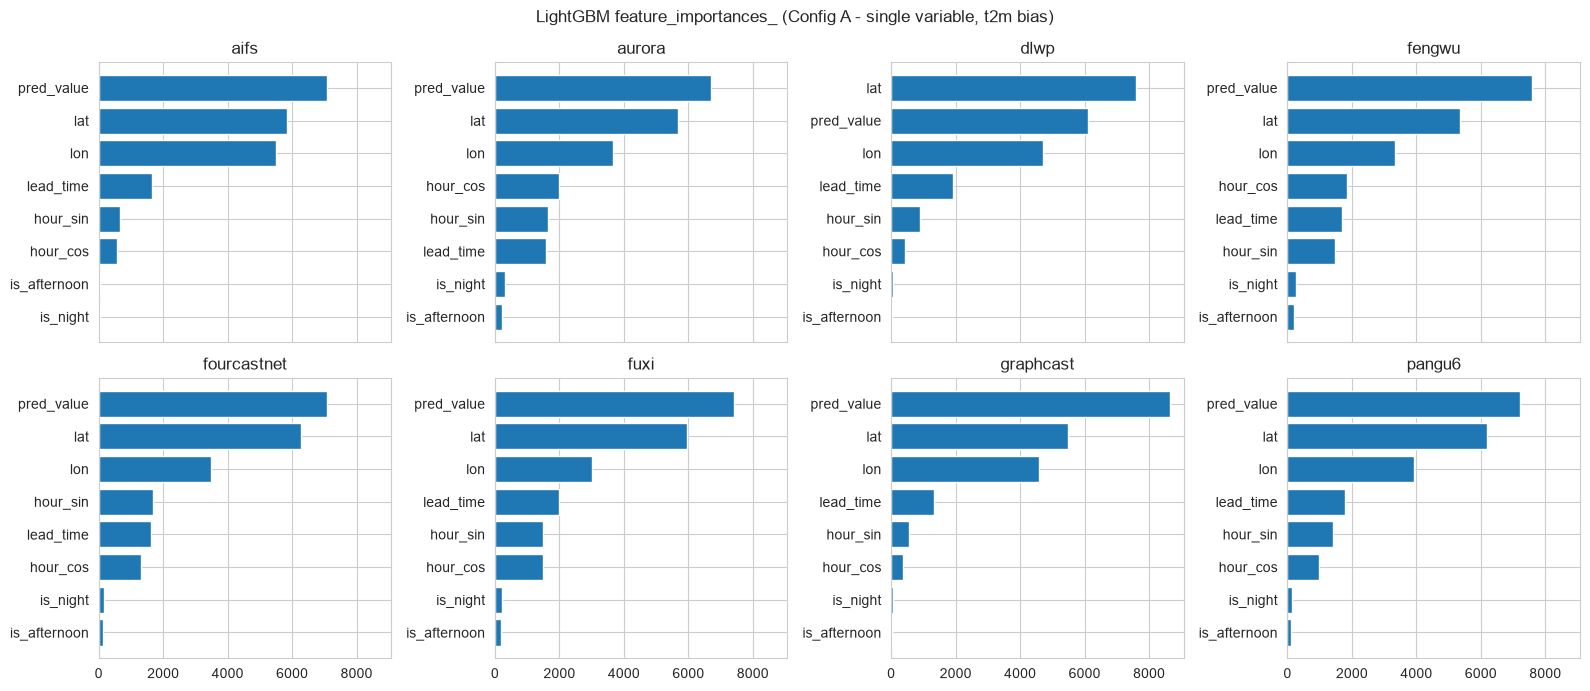

,aifs,aurora,dlwp,fengwu,fourcastnet,fuxi,graphcast,pangu6
pred_value,7073,6696,6109,7594,7087,7411,8643,7222
lat,5830,5671,7589,5351,6273,5962,5487,6194
lon,5513,3671,4724,3346,3480,2997,4595,3921
lead_time,1665,1571,1925,1680,1627,1995,1338,1772
hour_sin,671,1631,890,1473,1686,1499,555,1424
hour_cos,576,1971,440,1854,1300,1489,359,991
is_afternoon,49,215,17,200,130,184,13,97
is_night,40,324,56,252,167,213,56,129


In [46]:
# Feature importances for Config A LightGBM models
importances_single = {}
for weather_model, lgbm_model in lgbm_single_models.items():
    importances_single[weather_model] = pd.Series(lgbm_model.feature_importances_, index=FEATURES)

importances_single_df = pd.DataFrame(importances_single).round(4)
importances_single_df.to_csv(os.path.join('../results/tables', 'lgbm_feature_importance_single_t2m.csv'))

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
axes = axes.flatten()
for i, weather_model in enumerate(importances_single_df.columns):
    scores = importances_single_df[weather_model].sort_values(ascending=True)
    axes[i].barh(scores.index, scores.values)
    axes[i].set_title(weather_model)
plt.suptitle('LightGBM feature_importances_ (Config A - single variable, t2m bias)')
plt.tight_layout()
plt.savefig('../results/figures/lgbm_feature_importance_single_t2m.png')
plt.show()

importances_single_df


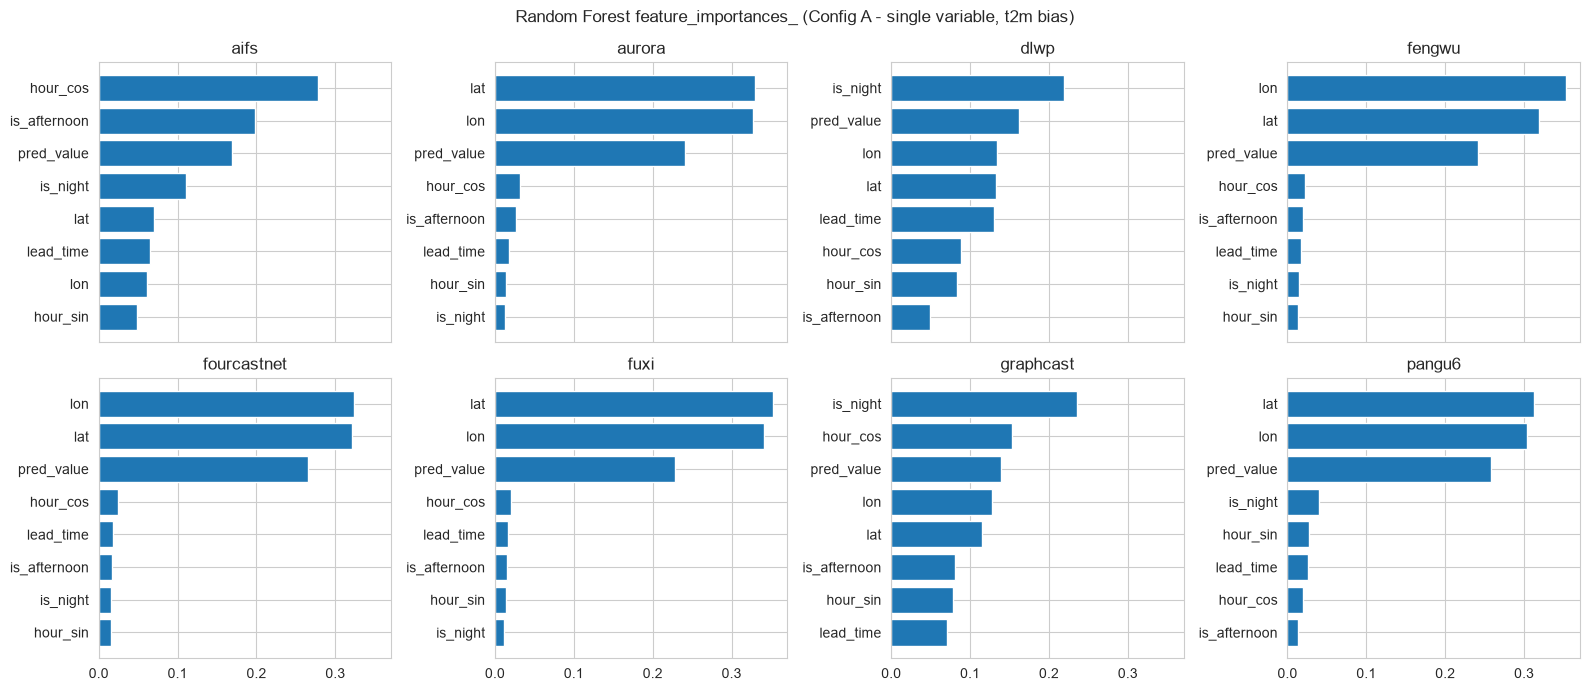

,aifs,aurora,dlwp,fengwu,fourcastnet,fuxi,graphcast,pangu6
pred_value,0.1684,0.2405,0.1619,0.2412,0.2648,0.2283,0.1396,0.2582
lat,0.0695,0.3294,0.1324,0.3194,0.3211,0.3531,0.1150,0.3122
lon,0.0617,0.3274,0.1347,0.3532,0.3236,0.3413,0.1281,0.3040
lead_time,0.0648,0.0172,0.1306,0.0168,0.0175,0.0171,0.0713,0.0254
hour_sin,0.0489,0.0134,0.0834,0.0132,0.0152,0.0137,0.0778,0.0270
hour_cos,0.2782,0.0319,0.0885,0.0228,0.0247,0.0200,0.1527,0.0203
is_afternoon,0.1975,0.0272,0.0492,0.0192,0.0171,0.0155,0.0807,0.0132
is_night,0.1110,0.0131,0.2193,0.0141,0.0160,0.0111,0.2349,0.0397


In [47]:
# Feature importances for Config A Random Forest models
rf_importances_single = {}
for weather_model, rf_model in rf_single_models.items():
    rf_importances_single[weather_model] = pd.Series(rf_model.feature_importances_, index=FEATURES)

rf_importances_single_df = pd.DataFrame(rf_importances_single).round(4)
rf_importances_single_df.to_csv(os.path.join('../results/tables', 'rf_feature_importance_single_t2m.csv'))

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
axes = axes.flatten()
for i, weather_model in enumerate(rf_importances_single_df.columns):
    scores = rf_importances_single_df[weather_model].sort_values(ascending=True)
    axes[i].barh(scores.index, scores.values)
    axes[i].set_title(weather_model)
plt.suptitle('Random Forest feature_importances_ (Config A - single variable, t2m bias)')
plt.tight_layout()
plt.savefig('../results/figures/rf_feature_importance_single_t2m.png')
plt.show()

rf_importances_single_df


In [48]:
# Same check for Config B LightGBM models, where available
importances_multi = {}

for weather_model, lgbm_model in lgbm_multi_models.items():
    n_features = len(lgbm_model.feature_importances_)

    other_vars = get_other_variables(weather_model, "t2m")

    multi_feature_names = ["pred_t2m"] + ["pred_" + v for v in other_vars] + BASE_FEATURES
    importances_multi[weather_model] = pd.Series(lgbm_model.feature_importances_, index=multi_feature_names[:n_features])

importances_multi_df = pd.DataFrame(importances_multi).round(4)
importances_multi_df.to_csv(os.path.join('../results/tables', 'lgbm_feature_importance_multi_t2m.csv'))
importances_multi_df


,aifs,aurora,fengwu,fourcastnet,fuxi,graphcast,pangu6
hour_cos,259,421.0,430.0,197.0,541.0,239.0,322.0
hour_sin,106,636.0,539.0,284.0,645.0,317.0,683.0
is_afternoon,29,36.0,37.0,19.0,27.0,7.0,14.0
is_night,13,37.0,32.0,32.0,83.0,43.0,38.0
lat,112,3406.0,3215.0,1220.0,3141.0,2489.0,3460.0
lead_time,111,819.0,707.0,346.0,628.0,575.0,783.0
lon,112,2904.0,2618.0,762.0,2026.0,2194.0,2568.0
pred_msl,176,3722.0,3685.0,1009.0,3135.0,3421.0,3562.0
pred_sp,485,NaN,NaN,1719.0,NaN,NaN,NaN
pred_t2m,535,4380.0,4488.0,1188.0,3274.0,4133.0,4076.0


In [49]:
# Same check for Config B Random Forest models, where available
rf_importances_multi = {}

for weather_model, rf_model in rf_multi_models.items():
    n_features = len(rf_model.feature_importances_)
    other_vars = get_other_variables(weather_model, "t2m")

    multi_feature_names = [ "pred_t2m" ] + ["pred_" + v for v in other_vars] + BASE_FEATURES
    rf_importances_multi[weather_model] = pd.Series(rf_model.feature_importances_, index=multi_feature_names[:n_features])

rf_importances_multi_df = pd.DataFrame(rf_importances_multi).round(4)
rf_importances_multi_df.to_csv(os.path.join('../results/tables', 'rf_feature_importance_multi_t2m.csv'))
rf_importances_multi_df


,aifs,aurora,fengwu,fourcastnet,fuxi,graphcast,pangu6
hour_cos,0.2433,0.0327,0.0237,0.0337,0.0210,0.0581,0.0207
hour_sin,0.0247,0.0194,0.0194,0.0241,0.0199,0.0716,0.0284
is_afternoon,0.2675,0.0366,0.0282,0.0370,0.0311,0.1054,0.0225
is_night,0.0487,0.0199,0.0216,0.0333,0.0193,0.2883,0.0779
lat,0.0141,0.2259,0.2260,0.1608,0.2368,0.0812,0.2202
lead_time,0.0198,0.0245,0.0230,0.0333,0.0206,0.0306,0.0319
lon,0.0194,0.2843,0.2980,0.1322,0.2632,0.0697,0.2183
pred_msl,0.0225,0.1433,0.1385,0.1128,0.1196,0.0995,0.1558
pred_sp,0.1005,NaN,NaN,0.2533,NaN,NaN,NaN
pred_t2m,0.1459,0.2133,0.2216,0.1796,0.1749,0.1227,0.2243


## Comparing Calibration Model Feature Importance with the EDA

The feature importance from **Random Forest** and **LightGBM** was compared with the mutual information results from Part 1.

| model | Part 1 (mutual info) | LightGBM top features | Random Forest top features |
|---|---|---|---|
| aifs | time-driven | pred_value, lat, lon | is_afternoon, hour_cos, pred_value |
| dlwp | time-driven | pred_value, lat, lon | is_night, pred_value, lat |
| graphcast | time-driven | pred_value, lat, lon | is_night, pred_value, lon |
| aurora | location-driven | pred_value, lat, lon | lat, lon, pred_value |
| fengwu | location-driven | pred_value, lat, lon | lon, lat, pred_value |
| fourcastnet | location-driven | pred_value, lat, lon | lon, lat, pred_value |
| fuxi | location-driven | pred_value, lat, lon | lat, lon, pred_value |
| pangu6 | location-driven | pred_value, lat, lon | lat, lon, pred_value |

**Random Forest agrees with the Part 1 results.** For **AIFS, DLWP, and GraphCast**, time-related features appear among the most important features, confirming that these models are mainly affected by the time of day. For the other models, **latitude and longitude** are the dominant features, confirming the location-based behavior found in the EDA.

**LightGBM gives a different result.** For all models, it ranks `pred_value`, `lat`, and `lon` as the most important features, while time features receive lower importance. This difference comes from the way feature importance is calculated. LightGBM builds trees sequentially and often favors continuous features such as latitude and longitude because they provide many possible split points. In comparison, Random Forest uses many independent trees with random feature selection, giving lower-cardinality features such as time indicators more chances to be selected.

Therefore, the disagreement does not necessarily mean that one method is wrong. Mutual information and Random Forest both support the same conclusion: some models are mainly influenced by **time features**, while others are mainly influenced by **location features**. LightGBM importance is useful but should be interpreted carefully because tree-based importance measures can be affected by feature type and number of possible splits.

## Step 8: Precipitation (`tp06`) Calibration

Precipitation is more difficult to calibrate because rainfall events are rare in the dataset. Section 12 of Part 1 showed that only about **1.3%–2.0%** of `tp06` bias values are non-zero. This creates a strong class imbalance, where most cases correspond to **no significant bias**.

Training a normal regression model directly on this data would make the model mainly predict **zero bias**, giving good average results but failing to correct the important rainfall cases.

To solve this problem, a **two-step approach** is used:

1. **Classification:** predict whether a significant precipitation bias exists or not.
2. **Regression:** only for cases classified as having a significant bias, predict the exact bias value.

To reduce the effect of class imbalance during the classification step:

- **SVC, Random Forest, and LightGBM** use `sample_weight`, giving more importance to the minority class.
- **MLP** does not support `sample_weight` in scikit-learn, so the minority class is oversampled in the training set only.

The test set is kept unchanged, so the reported precision, recall, and F1-score represent performance on the original precipitation distribution.

The two configurations are also tested:

- **Config A (single variable):** uses predicted `tp06` together with location and time features.
- **Config B (multi-parameter):** uses predicted `tp06` plus other available predicted weather variables, such as `t2m` and `msl`.

This approach is applied to the models providing precipitation forecasts: **AIFS, Fuxi, and GraphCast**.

In [50]:
def balance_classes(features_df, labels, random_state=42):

    features_df = features_df.reset_index(drop=True)
    labels = labels.reset_index(drop=True)

    rng = np.random.RandomState(random_state)
    idx_pos = labels[labels == 1].index.to_numpy()
    idx_neg = labels[labels == 0].index.to_numpy()

    if len(idx_pos) == 0 or len(idx_neg) == 0:
        # Nothing to balance against: return unchanged
        return features_df, labels

    n_target = max(len(idx_pos), len(idx_neg))
    idx_pos_bal = rng.choice(idx_pos, size=n_target, replace=True)
    idx_neg_bal = rng.choice(idx_neg, size=n_target, replace=True)
    idx_bal = np.concatenate([idx_pos_bal, idx_neg_bal])
    rng.shuffle(idx_bal)

    return features_df.loc[idx_bal].reset_index(drop=True), labels.loc[idx_bal].reset_index(drop=True)


In [51]:
def two_step_precipitation(weather_model, config="single", algorithm="mlp", threshold=0.1):

    if config == "single":
        subset = df[(df["model"] == weather_model) &(df["variable_name"] == "tp06")]
        features = FEATURES
        pred_column = "pred_value"
        train, test = split_train_test(subset)
    else:
        other_variables = get_other_variables(weather_model, "tp06")
        if len(other_variables) == 0:
            print(weather_model, ": no extra variables besides tp06. Skipping Config B.")
            return
        wide_table, features = build_multi_parameter_table(weather_model, "tp06", other_variables)
        pred_column = "pred_tp06"
        train, test = split_train_test(wide_table)

    # Step 1 target: classify whether the precipitation bias is significant.
    train_label = (train["biais"].abs() > threshold).astype(int)
    test_label = (test["biais"].abs() > threshold).astype(int)

    n_positive = train_label.sum()
    print(weather_model, "-", config, "-", algorithm, ": significant bias cases in train =",
          n_positive, "/", len(train_label))

    if n_positive < 20:
        print("  Not enough examples to train. Skipping this model.")
        return

    algorithm_names = {"mlp": "MLP", "svr": "SVR", "random_forest": "RandomForest", "lgbm": "LGBM"}
    algorithm_name = algorithm_names[algorithm]

    # --- Step 1: classification ---
    if algorithm in ("svr", "random_forest", "lgbm"):
        # These classifiers support sample_weight, so the rare significant-bias class
        # receives more importance during training.
        n_negative = len(train_label) - n_positive
        positive_weight = n_negative / n_positive
        sample_weight = np.where(train_label == 1, positive_weight, 1.0)

        if algorithm == "svr":
            # SVC needs scaled features because it uses distances between samples.
            x_scaler = StandardScaler().fit(train[features])
            x_train_clf = x_scaler.transform(train[features])
            x_test_clf = x_scaler.transform(test[features])
            classifier = SVC(kernel="rbf", C=148.96865493421592, gamma=0.008757610123288557, random_state=42)

            classifier.fit(x_train_clf, train_label, sample_weight=sample_weight)
            predicted_label = classifier.predict(x_test_clf)

        elif algorithm == "random_forest":
            classifier = RandomForestClassifier(n_estimators=462, max_depth=4, min_samples_split=36,min_samples_leaf=25, max_features=0.7776664458994712, max_samples=0.9934628585464654,random_state=42, n_jobs=-1)

            classifier.fit(train[features], train_label, sample_weight=sample_weight)
            predicted_label = classifier.predict(test[features])

        else:  # lgbm
            classifier = LGBMClassifier(n_estimators=546, max_depth=9, learning_rate=0.005281673048638902, num_leaves=25, subsample=0.9780713598118698, min_child_samples=80,colsample_bytree=0.7396765886951213, reg_alpha=1.3781196244988594, reg_lambda=0.3169351462725966,random_state=42, n_jobs=-1, verbosity=-1)

            classifier.fit(train[features], train_label, sample_weight=sample_weight)
            predicted_label = classifier.predict(test[features])

    else:
        # MLPClassifier does not support sample_weight, so the minority class
        # is oversampled in the training data to reduce class imbalance.
        # Hyperparameters were selected using manual search with oversampling.
        classifier = MLPClassifier(hidden_layer_sizes=(16,), alpha=0.000017, learning_rate_init=0.002780,max_iter=300, early_stopping=True, random_state=42)

        train_features_bal, train_label_bal = balance_classes(train[features], train_label)
        print("  After balancing: positive class now", int(train_label_bal.sum()), "/", len(train_label_bal))
        classifier.fit(train_features_bal, train_label_bal)
        predicted_label = classifier.predict(test[features])

    step1_scores = {
        "precision": round(precision_score(test_label, predicted_label, zero_division=0), 3),
        "recall": round(recall_score(test_label, predicted_label, zero_division=0), 3),
        "f1": round(f1_score(test_label, predicted_label, zero_division=0), 3),
    }
    print("  Step 1 scores:", step1_scores)

    # --- Step 2: regression only on rows with significant precipitation bias ---
    train_significant = train[train_label == 1]
    test_significant = test[test_label == 1]

    if len(train_significant) < 20 or len(test_significant) < 5:
        print("  Not enough significant rows for step 2. Stopping here.")
        save_result(algorithm_name, config, weather_model, "tp06", step1_scores, len(train_significant), len(test_significant))

        return

    # Step 2 regression uses the tuned regression hyperparameters from Config A.
    # tp06 uses the same feature structure as Config A, so separate tuning was not performed.
    if algorithm == "svr":
        x_scaler = StandardScaler().fit(train_significant[features])
        y_scaler = StandardScaler().fit(train_significant[["biais"]])
        x_train = x_scaler.transform(train_significant[features])
        y_train = y_scaler.transform(train_significant[["biais"]]).ravel()
        x_test = x_scaler.transform(test_significant[features])

        regressor = SVR(kernel="rbf", C=0.29663272054469436, epsilon=0.48277125473350574, gamma=0.07848845094209282)

        regressor.fit(x_train, y_train)
        pred_scaled = regressor.predict(x_test)
        predicted_value = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()

    elif algorithm == "random_forest":
        regressor = RandomForestRegressor(n_estimators=179, max_depth=22, min_samples_split=5,min_samples_leaf=10, max_features=0.36036833842338895, max_samples=0.6018991761512245,random_state=42, n_jobs=-1)

        regressor.fit(train_significant[features], train_significant["biais"])
        predicted_value = regressor.predict(test_significant[features])

    elif algorithm == "lgbm":
        regressor = LGBMRegressor(n_estimators=250, max_depth=12, learning_rate=0.011451844802259338, num_leaves=88,subsample=0.6745275586556285, min_child_samples=60, colsample_bytree=0.75261120564501,reg_alpha=0.003295732159059646, reg_lambda=0.0060924058597702615,random_state=42, n_jobs=-1, verbosity=-1)

        regressor.fit(train_significant[features], train_significant["biais"])
        predicted_value = regressor.predict(test_significant[features])

    else:
        # Scale inputs and target because MLP is sensitive to feature ranges.
        x_scaler = StandardScaler().fit(train_significant[features])
        y_scaler = StandardScaler().fit(train_significant[["biais"]])
        x_train = x_scaler.transform(train_significant[features])
        y_train = y_scaler.transform(train_significant[["biais"]]).ravel()
        x_test = x_scaler.transform(test_significant[features])

        regressor = MLPRegressor(hidden_layer_sizes=(64, 32), activation="tanh", alpha=0.0002920433847181409,learning_rate_init=0.000816845589476017, max_iter=300,early_stopping=True, random_state=42)

        regressor.fit(x_train, y_train)
        pred_scaled = regressor.predict(x_test)
        predicted_value = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()

    step2_scores = get_scores(test_significant["biais"], predicted_value)
    baseline_scores = compare_to_baseline(test_significant, predicted_value, pred_column=pred_column)

    print("  Step 2 scores:", step2_scores)

    all_scores = {**step1_scores, **step2_scores}
    save_result(algorithm_name, config, weather_model, "tp06", all_scores,
                len(train_significant), len(test_significant), baseline_scores)

In [52]:
models_with_precipitation = sorted(df[df["variable_name"] == "tp06"]["model"].unique())
print("Models with tp06:", models_with_precipitation)

print("\n**********************************************************\n")
for weather_model in models_with_precipitation:
    two_step_precipitation(weather_model, config="single", algorithm="mlp")
    two_step_precipitation(weather_model, config="single", algorithm="svr")
    two_step_precipitation(weather_model, config="single", algorithm="random_forest")
    two_step_precipitation(weather_model, config="single", algorithm="lgbm")
    two_step_precipitation(weather_model, config="multi", algorithm="mlp")
    two_step_precipitation(weather_model, config="multi", algorithm="svr")
    two_step_precipitation(weather_model, config="multi", algorithm="random_forest")
    two_step_precipitation(weather_model, config="multi", algorithm="lgbm")
    print("\n**********************************************************\n")

Models with tp06: ['aifs', 'fuxi', 'graphcast']

**********************************************************

aifs - single - mlp : significant bias cases in train = 442 / 18960
  After balancing: positive class now 18518 / 37036
  Step 1 scores: {'precision': 0.007, 'recall': 0.85, 'f1': 0.014}
  Step 2 scores: {'MAE': 1.538, 'RMSE': np.float64(2.368), 'R2': 0.05}
MLP             (single) | MAE: 1.538 | RMSE: 2.368 | R²: 0.050
aifs - single - svr : significant bias cases in train = 442 / 18960
  Step 1 scores: {'precision': 0.009, 'recall': 0.75, 'f1': 0.018}
  Step 2 scores: {'MAE': 1.549, 'RMSE': np.float64(2.438), 'R2': -0.008}
SVR             (single) | MAE: 1.549 | RMSE: 2.438 | R²: -0.008
aifs - single - random_forest : significant bias cases in train = 442 / 18960
  Step 1 scores: {'precision': 0.013, 'recall': 0.85, 'f1': 0.027}
  Step 2 scores: {'MAE': 1.373, 'RMSE': np.float64(2.208), 'R2': 0.174}
RandomForest    (single) | MAE: 1.373 | RMSE: 2.208 | R²: 0.174
aifs - single -

The **two-step approach** detects most significant precipitation errors (**recall: 0.50–0.88**), but **precision stays below 0.03** because rainfall events are very rare. **Config A** performs much better than **Config B**, while **Random Forest** gives the best calibration results with **R² up to 0.22**. Overall, precipitation remains the **most difficult variable to calibrate** due to the highly imbalanced dataset.

## Step 9: Final Results Table

All calibration results are collected into a single table and saved as a CSV file.

This table allows a direct comparison between:
- the four calibration algorithms (**MLP, SVR, Random Forest, and LightGBM**);
- the two configurations (**single variable and multi-parameter**);
- the different AI weather models and variables.

Saving the results in CSV format also makes it easier to analyze, rank, and visualize model performance later.

In [53]:
results_table = pd.DataFrame(all_results)
results_table.to_csv(os.path.join('../results/tables', 'calibration_results.csv'),index=False)

results_table.drop_duplicates(inplace = True)
results_table

,algorithm,config,weather_model,variable,n_train,n_test,MAE,RMSE,R2,raw_MAE,raw_RMSE,corrected_MAE,corrected_RMSE,RMSE_improvement_pct,MAE_improvement_pct,precision,recall,f1
0,MLP,single,aifs,t2m,19688,4923,2.244,2.931,0.694,4.084,5.304,2.244,2.931,44.7,45.0,NaN,NaN,NaN
1,SVR,single,aifs,t2m,19688,4923,2.307,3.008,0.678,4.084,5.304,2.307,3.008,43.3,43.5,NaN,NaN,NaN
2,RandomForest,single,aifs,t2m,19688,4923,2.248,2.943,0.692,4.084,5.304,2.248,2.943,44.5,45.0,NaN,NaN,NaN
3,LGBM,single,aifs,t2m,19688,4923,2.267,2.993,0.681,4.084,5.304,2.267,2.993,43.6,44.5,NaN,NaN,NaN
4,MLP,single,aurora,t2m,17179,4295,1.254,1.666,0.299,1.529,2.013,1.254,1.666,17.2,18.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,LGBM,single,graphcast,tp06,246,20,1.624,2.347,0.066,1.998,3.145,1.624,2.347,25.4,18.7,0.020,0.600,0.040
76,MLP,multi,graphcast,tp06,81,8,2.138,3.279,0.130,2.874,4.541,2.138,3.279,27.8,25.6,0.007,0.875,0.013
77,SVR,multi,graphcast,tp06,81,8,2.008,3.592,-0.044,2.874,4.541,2.008,3.592,20.9,30.1,0.014,0.625,0.028
78,RandomForest,multi,graphcast,tp06,81,8,2.175,3.553,-0.021,2.874,4.541,2.175,3.553,21.8,24.3,0.019,0.875,0.037


The final table confirms that **Random Forest** and **LightGBM** are the best overall calibration algorithms, with an average **RMSE of about 2.2**, while **SVR** remains the weakest. **Config B** improves the results for the tree-based models (**Random Forest** and **LightGBM**), but not for **MLP**. Finally, **tp06** is still the most difficult variable to calibrate, with **9 of the 20 experiments showing negative R²**, highlighting the challenge of correcting precipitation forecasts.

## Step 9b: Performance Before and After Bias Calibration

Evaluating how well the calibration models predict the bias is only an intermediate step. The final objective is to determine whether the bias correction actually improves the original AI weather forecasts.

Therefore, the calibrated forecasts are compared with the original forecasts on the same test samples:

- **Raw forecast error:** the error of the original AI model forecast before correction (`pred_value` compared with `obs_value`).
- **Corrected forecast error:** the error after applying the predicted bias correction (`pred_value - predicted_bias` compared with `obs_value`).
- **RMSE improvement:** the percentage change in RMSE after calibration. A positive value means that calibration reduced the forecast error, while a negative value means that the correction made the forecast worse.

The metrics:
- `raw_RMSE`
- `corrected_RMSE`
- `RMSE_improvement_pct`

are calculated automatically during training using the `compare_to_baseline` function. This section only summarizes the results to evaluate whether the calibration models provide a real improvement over the original AI forecasts.

In [54]:
comparison_cols = ["algorithm", "config", "weather_model", "variable", "n_test","raw_RMSE", "corrected_RMSE", "RMSE_improvement_pct","raw_MAE", "corrected_MAE", "MAE_improvement_pct"]

comparison_table = results_table[comparison_cols].copy()
comparison_table = comparison_table.sort_values(["variable", "config", "RMSE_improvement_pct"],ascending=[True, True, False])

comparison_table.drop_duplicates(inplace = True)
comparison_table.head(15)

,algorithm,config,weather_model,variable,n_test,raw_RMSE,corrected_RMSE,RMSE_improvement_pct,raw_MAE,corrected_MAE,MAE_improvement_pct
34,RandomForest,multi,aifs,t2m,211,4.926,2.512,49.0,3.749,1.967,47.5
32,MLP,multi,aifs,t2m,211,4.926,2.540,48.4,3.749,2.036,45.7
35,LGBM,multi,aifs,t2m,211,4.926,2.608,47.1,3.749,1.982,47.1
33,SVR,multi,aifs,t2m,211,4.926,2.658,46.0,3.749,2.070,44.8
55,LGBM,multi,graphcast,t2m,1386,4.208,3.173,24.6,3.294,2.495,24.3
54,RandomForest,multi,graphcast,t2m,1386,4.208,3.193,24.1,3.294,2.522,23.4
53,SVR,multi,graphcast,t2m,1386,4.208,3.282,22.0,3.294,2.569,22.0
52,MLP,multi,graphcast,t2m,1386,4.208,3.394,19.3,3.294,2.645,19.7
50,RandomForest,multi,fuxi,t2m,1427,2.210,1.806,18.3,1.692,1.371,18.9
42,RandomForest,multi,fengwu,t2m,1388,2.053,1.681,18.1,1.573,1.286,18.2


The **Top 15** results are dominated by **AIFS**, with **RMSE improvements of 46–49%**, and **Random Forest** achieving the best overall result (**49.0%**). **GraphCast** ranks second with **19–25%** improvement, while the other models improve by about **13–18%**. These results confirm that **models with the largest initial errors benefit the most from calibration**, especially **AIFS** and **GraphCast**.

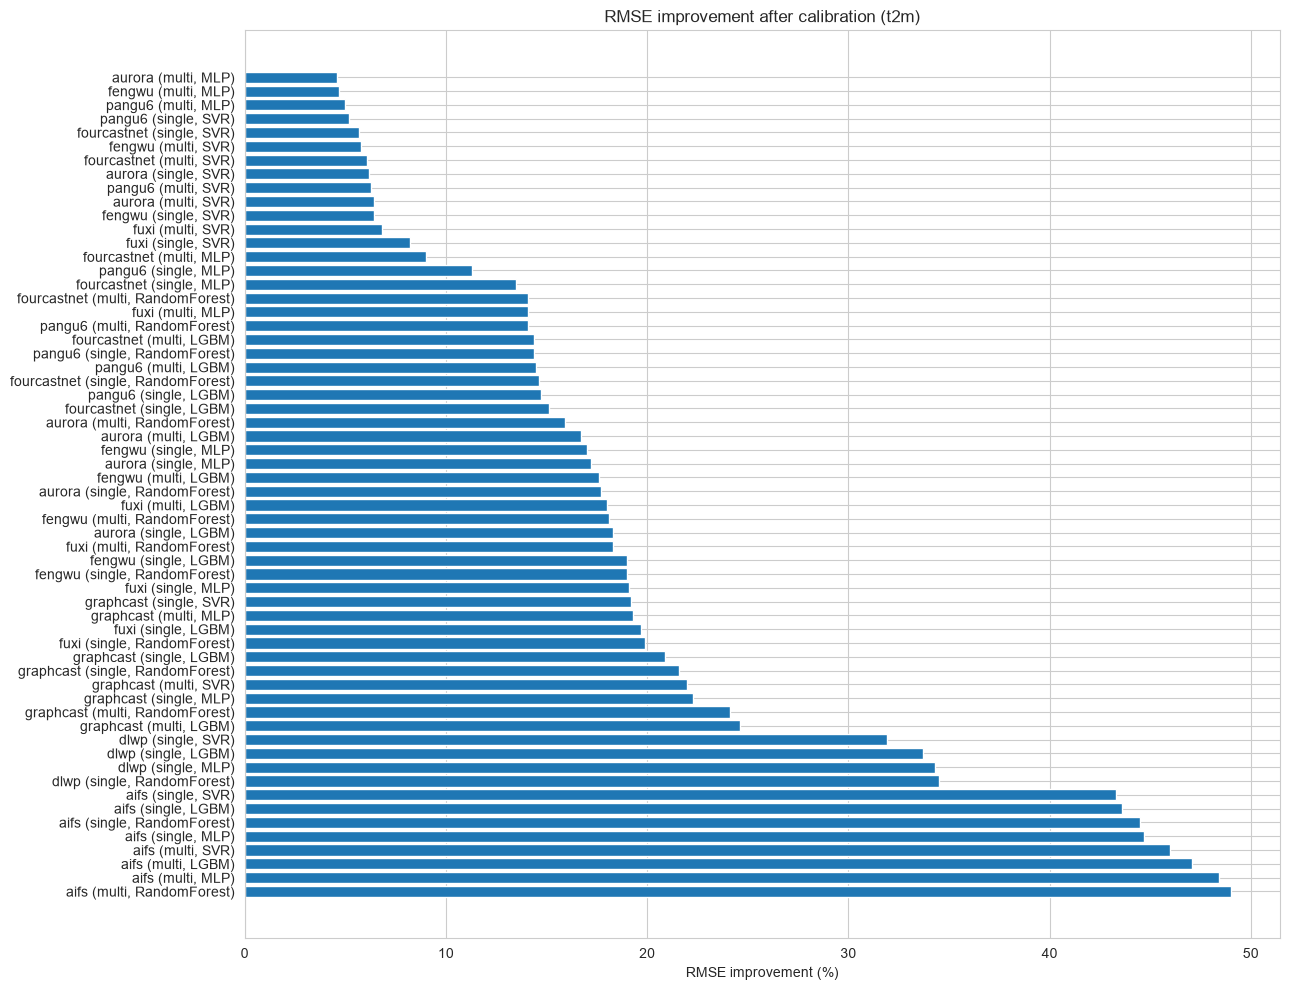

In [55]:
t2m_comparison = comparison_table[comparison_table["variable"] == "t2m"].copy()
t2m_comparison["label"] = t2m_comparison["weather_model"] + " (" + t2m_comparison["config"] + ", " + t2m_comparison["algorithm"] + ")"
t2m_comparison = t2m_comparison.sort_values("RMSE_improvement_pct",ascending=False)

plt.figure(figsize=(13, 10))
plt.barh(t2m_comparison["label"], t2m_comparison["RMSE_improvement_pct"])
plt.xlabel("RMSE improvement (%)")
plt.title("RMSE improvement after calibration (t2m)")
plt.tight_layout()
plt.show()

A positive RMSE improvement value indicates that the calibration successfully reduced the forecast error. Values close to **0%** indicate little or no change, while negative values mean that the correction made the forecast less accurate. Small degradations can occur, especially when the test set contains few samples or when the original AI forecast is already close to the observations.

## Step 9c: Checking an Early Prediction from Part 1

In Part 1 (Section 6), the models were ranked by RMSE. The results showed that **AIFS, DLWP, and GraphCast** had the largest forecast errors.

At that stage, it was expected that these models would benefit the most from calibration because they had the largest biases and therefore the greatest potential for improvement. However, this was only a hypothesis based on the original forecast errors.

After training and evaluating the calibration models, we can now compare the actual RMSE improvements and verify whether this initial expectation was correct.

In [56]:
# Keep only t2m, Config A, the config used in the original Part 1 comparison
check_table = comparison_table[(comparison_table["variable"] == "t2m") & (comparison_table["config"] == "single")]

# For each model, keep only the highest RMSE improvement, among the 4 algorithms
best_improvement = check_table.groupby("weather_model")["RMSE_improvement_pct"].max()

# Sort from the biggest improvement to the smallest
best_improvement = best_improvement.sort_values(ascending=False)

print("Best RMSE improvement (%) per model, Config A, t2m:")
best_improvement

Best RMSE improvement (%) per model, Config A, t2m:


weather_model
aifs           44.7
dlwp           34.5
graphcast      22.3
fuxi           19.9
fengwu         19.0
aurora         18.3
fourcastnet    15.1
pangu6         14.7
Name: RMSE_improvement_pct, dtype: float64

The results confirm the prediction from **Part 1**: the models with the largest initial errors gain the most from calibration. **AIFS** shows the biggest improvement (**≈45%**), followed by **DLWP (≈35%)** and **GraphCast (≈22%)**. The other models also improve, but by a smaller amount (**about 15–20%**). This confirms that **bias calibration is most effective for models with larger systematic errors**.

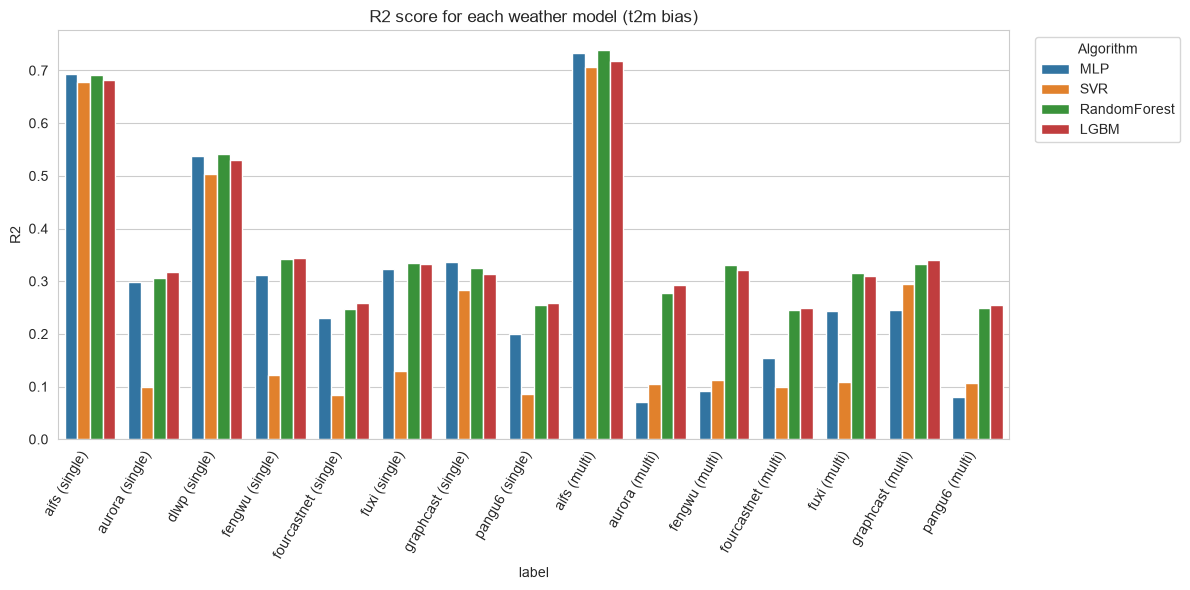

In [57]:
t2m_results = results_table[results_table["variable"] == "t2m"].copy()
t2m_results["label"] = t2m_results["weather_model"] + " (" + t2m_results["config"] + ")"

plt.figure(figsize=(12, 6))
sns.barplot(data=t2m_results, x="label", y="R2", hue="algorithm")
plt.xticks(rotation=60, ha="right")
plt.title("R2 score for each weather model (t2m bias)")
plt.legend(title='Algorithm', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

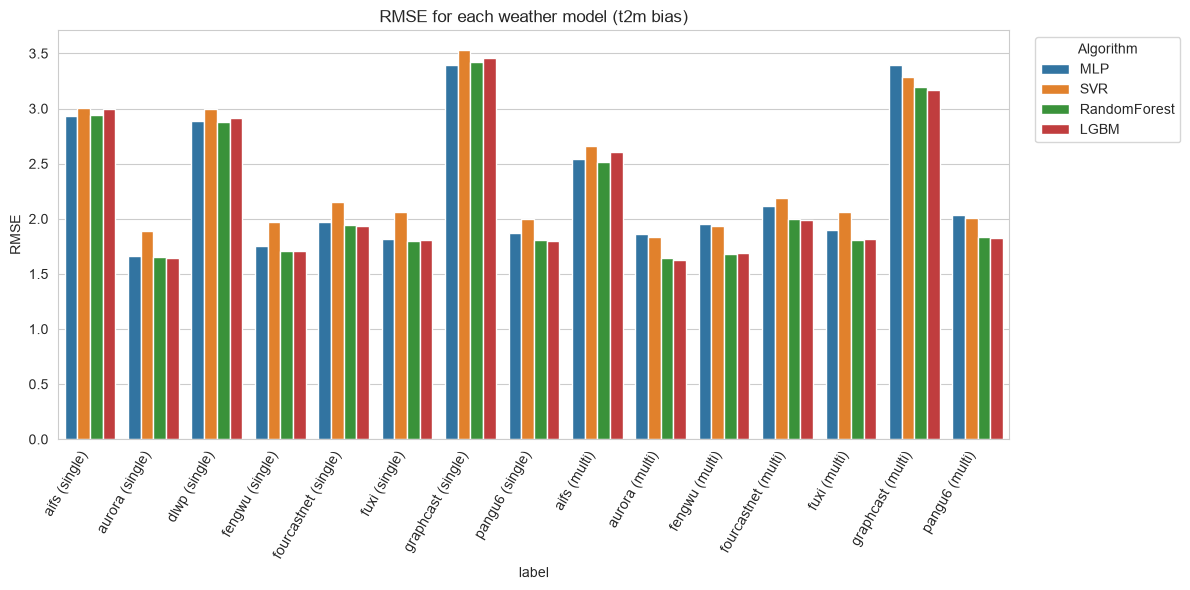

In [58]:
plt.figure(figsize=(12, 6))
sns.barplot(data=t2m_results, x="label", y="RMSE", hue="algorithm")
plt.xticks(rotation=60, ha="right")
plt.title("RMSE for each weather model (t2m bias)")
plt.legend(title='Algorithm', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

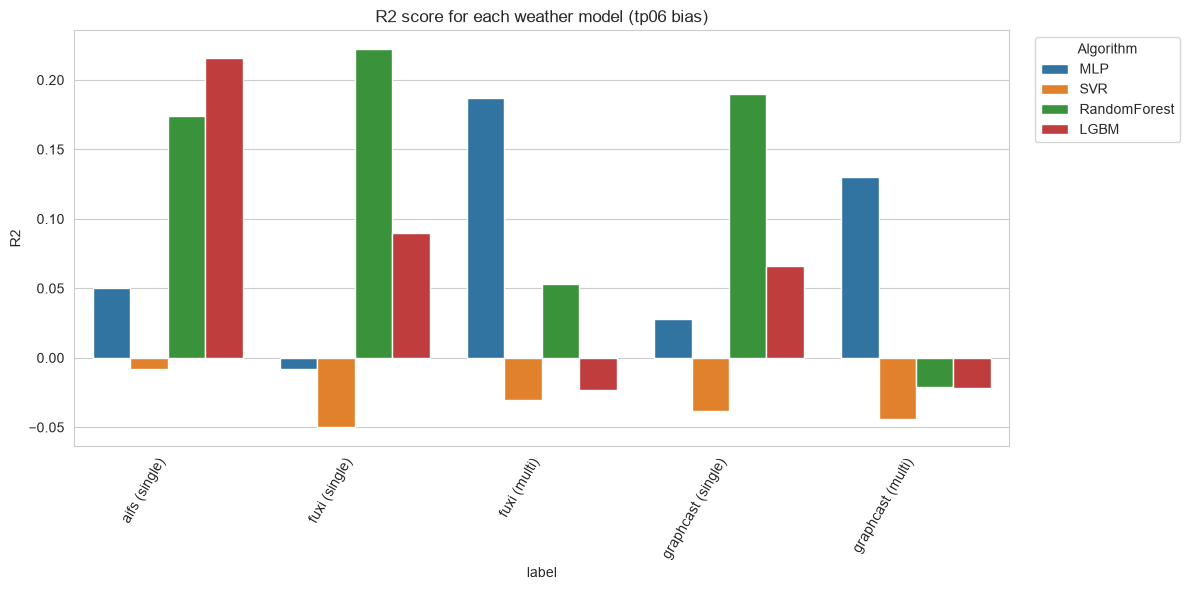

In [59]:
tp06_results = results_table[results_table["variable"] == "tp06"].copy()
tp06_results["label"] = tp06_results["weather_model"] + " (" + tp06_results["config"] + ")"

plt.figure(figsize=(12, 6))
sns.barplot(data=tp06_results, x="label", y="R2", hue="algorithm")
plt.xticks(rotation=60, ha="right")
plt.title("R2 score for each weather model (tp06 bias)")
plt.legend(title='Algorithm', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

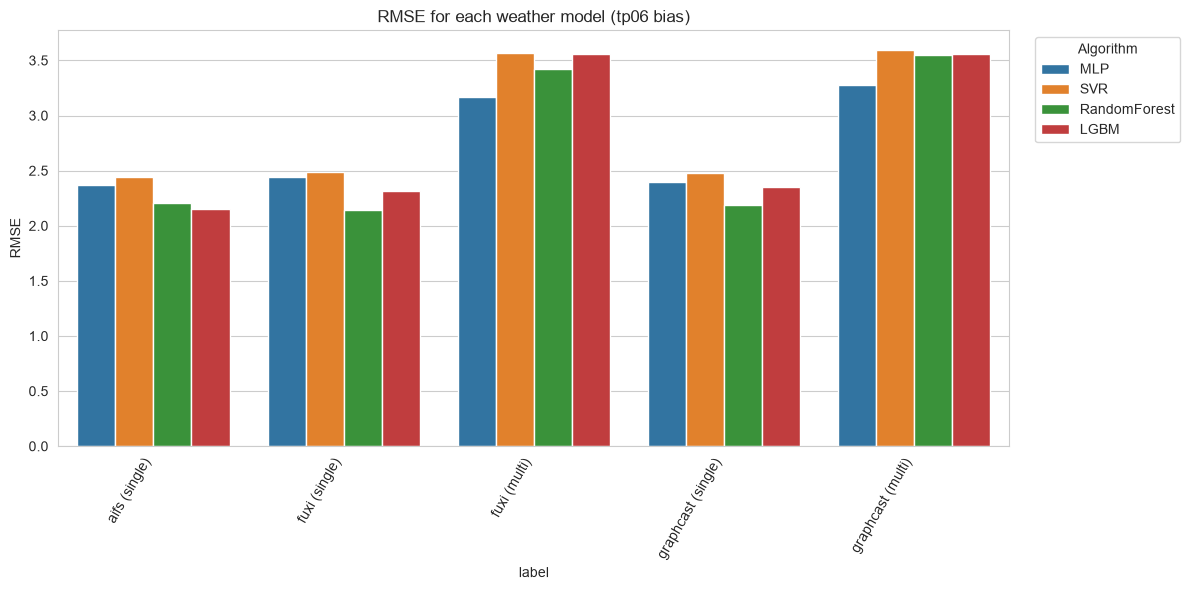

In [60]:
plt.figure(figsize=(12, 6))
sns.barplot(data=tp06_results, x="label", y="RMSE", hue="algorithm")
plt.xticks(rotation=60, ha="right")
plt.title("RMSE for each weather model (tp06 bias)")
plt.legend(title='Algorithm', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Conclusion

**The most useful calibration features depend on the AI weather model.** Based on mutual information and Random Forest feature importance, **AIFS, DLWP, and GraphCast** are mainly influenced by the **hour of the day**, while **Aurora, Fengwu, FourCastNet, Fuxi, and Pangu6** are more affected by **station location** (**latitude and longitude**). This time-vs-location separation is supported by the **ANOVA test** (Section 16), the **mutual information analysis** (Section 17), and **Random Forest feature importance** (Step 7b). LightGBM gives a different ranking, with `pred_value`, `lat`, and `lon` dominating for all models. This difference is likely related to the way boosting-based importance measures favor continuous features with many possible split points. Since mutual information and Random Forest agree, the identified feature patterns are considered reliable.

**Random Forest and LightGBM achieved the best calibration performance.** Among the four tested algorithms (**MLP, SVR, Random Forest, and LightGBM**), **Random Forest** provided the most consistent improvements, reducing RMSE by approximately **9–11%** on all tested models. **LightGBM** was often the best or second-best model, while **MLP** provided smaller but stable improvements. **SVR** showed the weakest performance, with the lowest R² values across the tested models.

**Config A captured most of the available information.** The **single-variable configuration** performed well for all 8 AI models. Although **Config B** allowed the use of additional predicted weather variables, its much smaller dataset (**842 samples compared with about 20,000 in Config A**) increased the risk of overfitting during hyperparameter tuning. For some algorithms, especially **SVR and LightGBM**, reusing Config A hyperparameters gave better generalization.

**Precipitation (`tp06`) remained the most challenging variable to calibrate.** Because almost all precipitation bias values are close to zero, the dataset is highly imbalanced. The proposed **two-step approach** (classification followed by regression) allowed the models to focus on significant precipitation errors, but the limited number of rainfall cases remained the main limitation.

**Calibration provides the greatest benefit for models with larger initial errors.** Models such as **AIFS, DLWP, and GraphCast**, which had the highest RMSE before calibration, achieved the largest improvements after correction. This confirms that models with larger systematic errors have greater potential to benefit from bias calibration.